<a href="https://colab.research.google.com/github/huyhoangk5/Nhom03_BTL_BDA/blob/main/Nhom03_BTL_BDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Khám phá, phân tích, trực quan hóa dữ liệu


In [1]:
%pip install -q pandas numpy matplotlib seaborn scipy "kagglehub[pandas-datasets]" scikit-learn xgboost joblib shap

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import os
import zipfile
import pandas as pd
import kagglehub

# Tải hoặc lấy đường dẫn dataset từ cache
dataset_path = kagglehub.dataset_download("ankitbatra1210/diabetes-dataset")
file_path = os.path.join(dataset_path, "diabetes_dataset00.csv")

# Tự động nhận diện: nếu file là zip thì đọc nén, nếu là CSV thường thì đọc trực tiếp
if zipfile.is_zipfile(file_path):
    df = pd.read_csv(file_path, compression="zip")
else:
    df = pd.read_csv(file_path)

print(df.shape)
df.head()

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_20336\3639273174.py:4: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


ValueError: Error reading file: 'utf-8' codec can't decode byte 0xf9 in position 10: invalid start byte

In [ ]:
#Tổng quan dữ liệu
print(df.shape)
print("Số ô thiếu: ", df.isna().sum().sum())
print ("Số ô dòng trùng: ", df.duplicated().sum())
df.info()
df.head()

(70000, 34)
Số ô thiếu:  0
Số ô dòng trùng:  0
<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 34 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   Target                         70000 non-null  str  
 1   Genetic Markers                70000 non-null  str  
 2   Autoantibodies                 70000 non-null  str  
 3   Family History                 70000 non-null  str  
 4   Environmental Factors          70000 non-null  str  
 5   Insulin Levels                 70000 non-null  int64
 6   Age                            70000 non-null  int64
 7   BMI                            70000 non-null  int64
 8   Physical Activity              70000 non-null  str  
 9   Dietary Habits                 70000 non-null  str  
 10  Blood Pressure                 70000 non-null  int64
 11  Cholesterol Levels             70000 non-null  int64
 12  Waist Circumference            70000 n

,Target,Genetic Markers,Autoantibodies,Family History,Environmental Factors,Insulin Levels,Age,BMI,Physical Activity,Dietary Habits,...,Pulmonary Function,Cystic Fibrosis Diagnosis,Steroid Use History,Genetic Testing,Neurological Assessments,Liver Function Tests,Digestive Enzyme Levels,Urine Test,Birth Weight,Early Onset Symptoms
0,Steroid-Induced Diabetes,Positive,Negative,No,Present,40,44,38,High,Healthy,...,76,No,No,Positive,3,Normal,56,Ketones Present,2629,No
1,Neonatal Diabetes Mellitus (NDM),Positive,Negative,No,Present,13,1,17,High,Healthy,...,60,Yes,No,Negative,1,Normal,28,Glucose Present,1881,Yes
2,Prediabetic,Positive,Positive,Yes,Present,27,36,24,High,Unhealthy,...,80,Yes,No,Negative,1,Abnormal,55,Ketones Present,3622,Yes
3,Type 1 Diabetes,Negative,Positive,No,Present,8,7,16,Low,Unhealthy,...,89,Yes,No,Positive,2,Abnormal,60,Ketones Present,3542,No
4,Wolfram Syndrome,Negative,Negative,Yes,Present,17,10,17,High,Healthy,...,41,No,No,Positive,1,Normal,24,Protein Present,1770,No


In [ ]:
#Phân loại các cột (Cột số và cột chữ)
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.drop('Target').to_list()
print(len(num_cols),"cột số: ", num_cols)
print(len(cat_cols),"cột chữ: ", cat_cols)
print(df[cat_cols].nunique())

13 cột số:  ['Insulin Levels', 'Age', 'BMI', 'Blood Pressure', 'Cholesterol Levels', 'Waist Circumference', 'Blood Glucose Levels', 'Weight Gain During Pregnancy', 'Pancreatic Health', 'Pulmonary Function', 'Neurological Assessments', 'Digestive Enzyme Levels', 'Birth Weight']
20 cột chữ:  ['Genetic Markers', 'Autoantibodies', 'Family History', 'Environmental Factors', 'Physical Activity', 'Dietary Habits', 'Ethnicity', 'Socioeconomic Factors', 'Smoking Status', 'Alcohol Consumption', 'Glucose Tolerance Test', 'History of PCOS', 'Previous Gestational Diabetes', 'Pregnancy History', 'Cystic Fibrosis Diagnosis', 'Steroid Use History', 'Genetic Testing', 'Liver Function Tests', 'Urine Test', 'Early Onset Symptoms']
Genetic Markers                  2
Autoantibodies                   2
Family History                   2
Environmental Factors            2
Physical Activity                3
Dietary Habits                   2
Ethnicity                        2
Socioeconomic Factors            

In [ ]:
#Thống kê mô tả  của các loại chỉ số
stats = df[num_cols].describe().T
stats['skew'] = df[num_cols].skew()
stats = stats.round(2)
stats

,count,mean,std,min,25%,50%,75%,max,skew
Insulin Levels,70000.0,21.61,10.79,5.0,13.0,19.0,28.00,49.0,0.71
Age,70000.0,32.02,21.04,0.0,14.0,31.0,49.00,79.0,0.23
BMI,70000.0,24.78,6.01,12.0,20.0,25.0,29.00,39.0,0.09
Blood Pressure,70000.0,111.34,19.94,60.0,99.0,113.0,125.00,149.0,-0.38
Cholesterol Levels,70000.0,194.87,44.53,100.0,163.0,191.0,225.00,299.0,0.26
Waist Circumference,70000.0,35.05,6.80,20.0,30.0,34.0,39.00,54.0,0.37
Blood Glucose Levels,70000.0,160.70,48.17,80.0,121.0,152.0,194.00,299.0,0.62
Weight Gain During Pregnancy,70000.0,15.50,9.63,0.0,7.0,16.0,22.00,39.0,0.16
Pancreatic Health,70000.0,47.56,19.98,10.0,32.0,46.0,64.00,99.0,0.18
Pulmonary Function,70000.0,70.26,11.97,30.0,63.0,72.0,79.00,89.0,-0.81


In [ ]:
#Phát hiện ngoại lai theo quy tắc IQR
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
low = Q1- 1.5*IQR
high = Q3 + 1.5*IQR
n_outliers = ((df[num_cols]<low) | (df[num_cols]>high)).sum()
n_outliers

Insulin Levels                     0
Age                                0
BMI                                0
Blood Pressure                     0
Cholesterol Levels                 0
Waist Circumference              522
Blood Glucose Levels               0
Weight Gain During Pregnancy       0
Pancreatic Health                  0
Pulmonary Function              1206
Neurological Assessments           0
Digestive Enzyme Levels            0
Birth Weight                       0
dtype: int64

In [ ]:
display(stats)


,count,mean,std,min,25%,50%,75%,max,skew
Insulin Levels,70000.0,21.61,10.79,5.0,13.0,19.0,28.00,49.0,0.71
Age,70000.0,32.02,21.04,0.0,14.0,31.0,49.00,79.0,0.23
BMI,70000.0,24.78,6.01,12.0,20.0,25.0,29.00,39.0,0.09
Blood Pressure,70000.0,111.34,19.94,60.0,99.0,113.0,125.00,149.0,-0.38
Cholesterol Levels,70000.0,194.87,44.53,100.0,163.0,191.0,225.00,299.0,0.26
Waist Circumference,70000.0,35.05,6.80,20.0,30.0,34.0,39.00,54.0,0.37
Blood Glucose Levels,70000.0,160.70,48.17,80.0,121.0,152.0,194.00,299.0,0.62
Weight Gain During Pregnancy,70000.0,15.50,9.63,0.0,7.0,16.0,22.00,39.0,0.16
Pancreatic Health,70000.0,47.56,19.98,10.0,32.0,46.0,64.00,99.0,0.18
Pulmonary Function,70000.0,70.26,11.97,30.0,63.0,72.0,79.00,89.0,-0.81


In [ ]:
#Đếm số mẫu và tỷ lệ từng lớp
counts = df['Target'].value_counts()
pct = (counts/len(df)*100).round(2)
bang_lop = pd.DataFrame({'Số mẫu':counts,' Tỷ lệ(%)': pct})
print(bang_lop)
ti_le = counts.max()/counts.min()
print(f'Imbalance ratio (lớn nhất/nhỏ nhất) = {ti_le:.3f}')
print(f'Số mẫu kỳ vọng nêu mỗi lớp cân bằng là: {len(df)/13:.0f}')

                                            Số mẫu   Tỷ lệ(%)
Target                                                       
MODY                                          5553       7.93
Secondary Diabetes                            5479       7.83
Cystic Fibrosis-Related Diabetes (CFRD)       5464       7.81
Type 1 Diabetes                               5446       7.78
Neonatal Diabetes Mellitus (NDM)              5408       7.73
Wolcott-Rallison Syndrome                     5400       7.71
Type 2 Diabetes                               5397       7.71
Prediabetic                                   5376       7.68
Gestational Diabetes                          5344       7.63
Type 3c Diabetes (Pancreatogenic Diabetes)    5320       7.60
Wolfram Syndrome                              5315       7.59
Steroid-Induced Diabetes                      5275       7.54
LADA                                          5223       7.46
Imbalance ratio (lớn nhất/nhỏ nhất) = 1.063
Số mẫu kỳ vọng nêu mỗi lớp

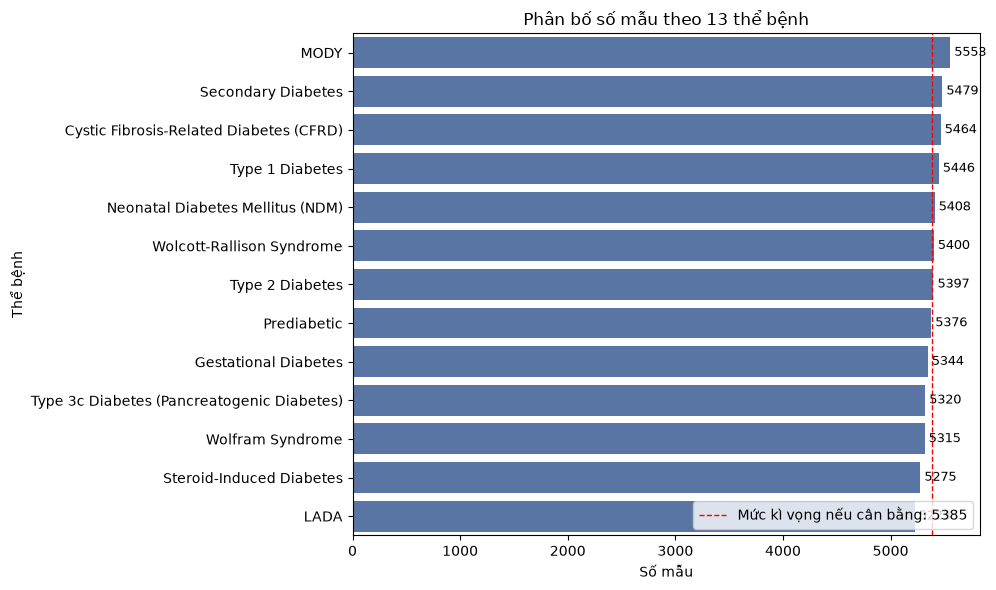

In [ ]:
#Vẽ biểu đồ cột
fig,ax = plt.subplots(figsize=(10,6))
sns.countplot(data=df,y='Target', order=counts.index,color='#4c72b0',ax=ax)
for c in ax.containers:
  ax.bar_label(c,fmt='%d', padding=3,fontsize=9)
  ax.axvline(len(df)/13,color='red',linestyle='--', linewidth=1,
             label=f'Mức kì vọng nếu cân bằng: {len(df)/13:.0f}')
ax.set_title('Phân bố số mẫu theo 13 thể bệnh')
ax.set_xlabel('Số mẫu'); ax.set_ylabel('Thể bệnh')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
#Kiểm định thống kê
from scipy.stats import chisquare

chi2, p = chisquare(counts.values)     # mặc định: so với phân phối đều
print(f"chi2 = {chi2:.2f}, p = {p:.4f}")

# Entropy chuẩn hóa: 1.0 là phân phối đều hoàn toàn
prob = counts / counts.sum()
entropy = -(prob * np.log(prob)).sum() / np.log(len(counts))
print(f"Entropy chuẩn hóa = {entropy:.4f}")

chi2 = 18.04, p = 0.1144
Entropy chuẩn hóa = 0.9999


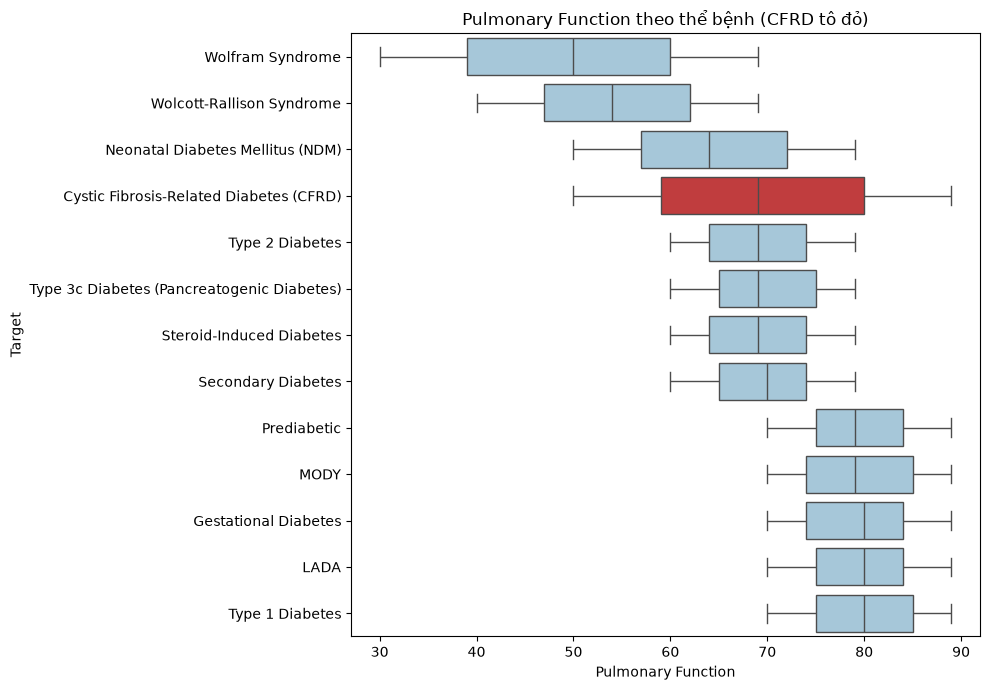

In [ ]:
#Boxplot Pulmonary Function theo thể bệnh
order = df.groupby('Target')['Pulmonary Function'].median().sort_values().index
palette = {t: ('#d62728' if t.startswith('Cystic') else '#9ecae1') for t in order}

plt.figure(figsize=(10, 7))
sns.boxplot(data=df, y='Target', x='Pulmonary Function', order=order,
            hue='Target', palette=palette, legend=False)
plt.title('Pulmonary Function theo thể bệnh (CFRD tô đỏ)')
plt.tight_layout()
plt.show()

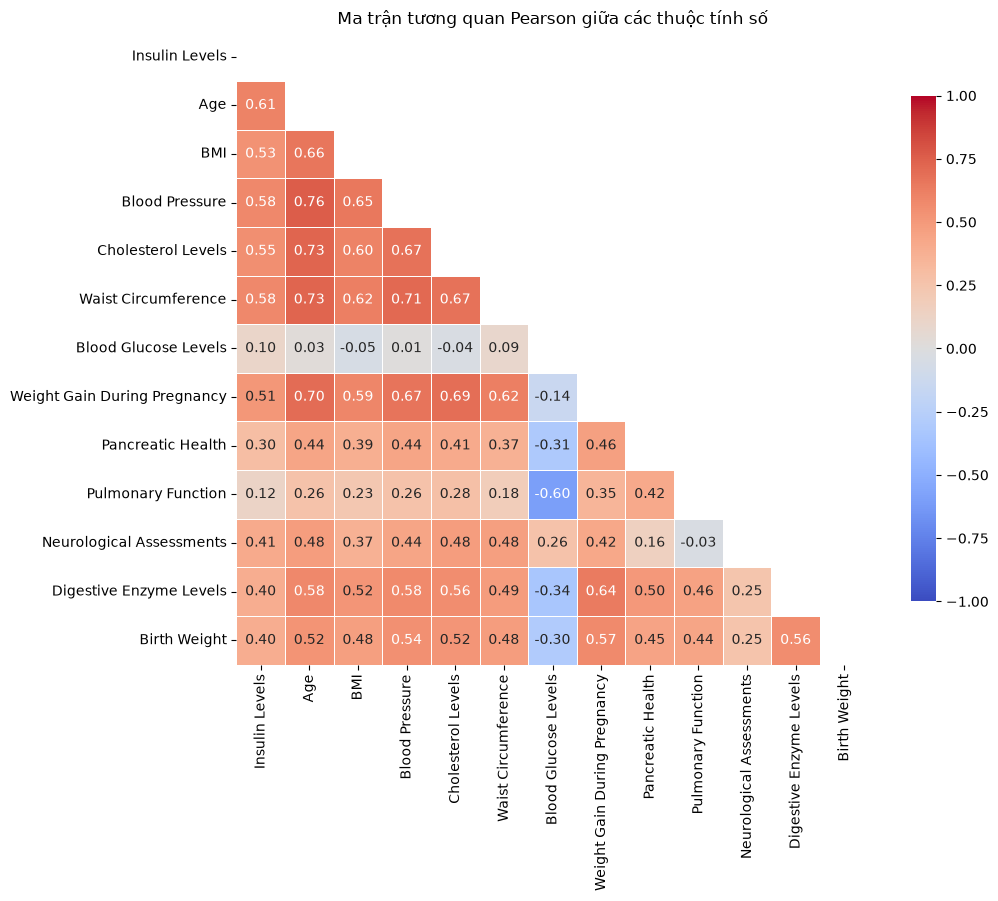

Blood Pressure                Age                   0.763
Waist Circumference           Age                   0.734
Cholesterol Levels            Age                   0.730
Waist Circumference           Blood Pressure        0.713
Weight Gain During Pregnancy  Age                   0.698
                              Cholesterol Levels    0.692
Cholesterol Levels            Blood Pressure        0.675
Waist Circumference           Cholesterol Levels    0.673
dtype: float64


In [ ]:
corr = df[num_cols].corr()                       # mặc định: Pearson
mask = np.triu(np.ones_like(corr, dtype=bool))   # ẩn nửa trên (đối xứng, lặp lại)

plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8})
plt.title('Ma trận tương quan Pearson giữa các thuộc tính số')
plt.tight_layout()
plt.show()

# Liệt kê các cặp tương quan mạnh nhất
pairs = corr.where(~mask).stack().sort_values(key=abs, ascending=False)
print(pairs.head(8).round(3))

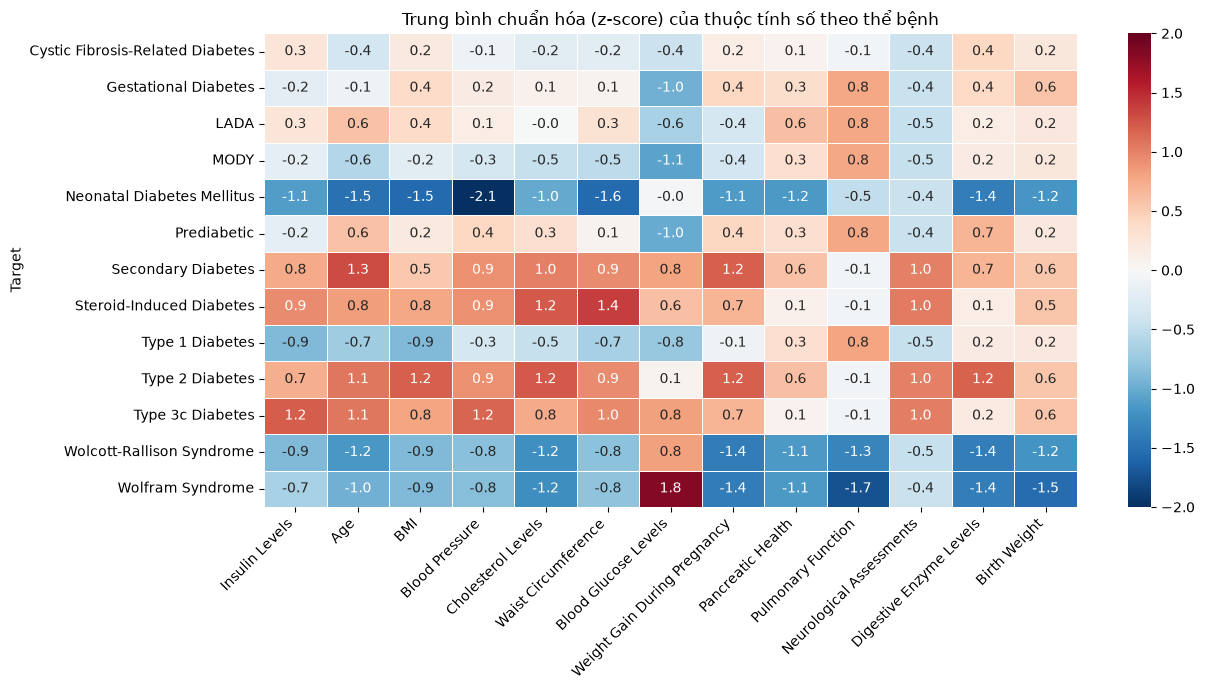

In [ ]:
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()   # chuẩn hóa z-score
z['Target'] = df['Target']
profile = z.groupby('Target').mean()
profile.index = profile.index.str.replace(r' \(.*\)', '', regex=True)  # rút gọn tên

plt.figure(figsize=(13, 7))
sns.heatmap(profile, annot=True, fmt='.1f', cmap='RdBu_r', center=0,
            vmin=-2, vmax=2, linewidths=0.5)
plt.title('Trung bình chuẩn hóa (z-score) của thuộc tính số theo thể bệnh')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df['Target'])

for i, ten in enumerate(le.classes_):
    print(i, ten)

0 Cystic Fibrosis-Related Diabetes (CFRD)
1 Gestational Diabetes
2 LADA
3 MODY
4 Neonatal Diabetes Mellitus (NDM)
5 Prediabetic
6 Secondary Diabetes
7 Steroid-Induced Diabetes
8 Type 1 Diabetes
9 Type 2 Diabetes
10 Type 3c Diabetes (Pancreatogenic Diabetes)
11 Wolcott-Rallison Syndrome
12 Wolfram Syndrome


In [ ]:
BINARY_MAP = {   # (giá trị mã hóa 0, giá trị mã hóa 1)
    'Genetic Markers': ('Negative', 'Positive'), 'Autoantibodies': ('Negative', 'Positive'),
    'Family History': ('No', 'Yes'), 'Environmental Factors': ('Absent', 'Present'),
    'Dietary Habits': ('Healthy', 'Unhealthy'), 'Ethnicity': ('Low Risk', 'High Risk'),
    'Smoking Status': ('Non-Smoker', 'Smoker'), 'Glucose Tolerance Test': ('Normal', 'Abnormal'),
    'History of PCOS': ('No', 'Yes'), 'Previous Gestational Diabetes': ('No', 'Yes'),
    'Pregnancy History': ('Normal', 'Complications'), 'Cystic Fibrosis Diagnosis': ('No', 'Yes'),
    'Steroid Use History': ('No', 'Yes'), 'Genetic Testing': ('Negative', 'Positive'),
    'Liver Function Tests': ('Normal', 'Abnormal'), 'Early Onset Symptoms': ('No', 'Yes'),
}
ORDINAL_MAP = {
    'Physical Activity':     {'Low': 0, 'Moderate': 1, 'High': 2},
    'Socioeconomic Factors': {'Low': 0, 'Medium': 1,   'High': 2},
    'Alcohol Consumption':   {'Low': 0, 'Moderate': 1, 'High': 2},
}
URINE_CATS = ['Glucose Present', 'Ketones Present', 'Protein Present']

def encode_features(data):
    out = data.copy()
    for col, (neg, pos) in BINARY_MAP.items():
        out[col] = out[col].map({neg: 0, pos: 1})
        assert out[col].notna().all(), f'Giá trị lạ ở cột {col}'
        out[col] = out[col].astype(int)
    for col, mp in ORDINAL_MAP.items():
        out[col] = out[col].map(mp)
        assert out[col].notna().all(), f'Giá trị lạ ở cột {col}'
        out[col] = out[col].astype(int)
    assert out['Urine Test'].isin(['Normal'] + URINE_CATS).all(), 'Giá trị lạ ở Urine Test'
    for cat in URINE_CATS:
        out[f'Urine Test_{cat}'] = (out['Urine Test'] == cat).astype(int)
    return out.drop(columns='Urine Test')

In [ ]:
X = df.drop(columns='Target')
X_enc = encode_features(X)
print(X_enc.shape)                              # kỳ vọng (70000, 35)
print(X_enc.select_dtypes('object').shape[1])   # kỳ vọng 0: không còn cột chữ
print(X_enc.dtypes.value_counts())              # toàn bộ phải là số
print(X_enc[['Autoantibodies', 'Dietary Habits']].mean())   # kỳ vọng ≈ 0,5
X_enc.head()

(70000, 35)
0
int64    35
Name: count, dtype: int64
Autoantibodies    0.499171
Dietary Habits    0.499714
dtype: float64


,Genetic Markers,Autoantibodies,Family History,Environmental Factors,Insulin Levels,Age,BMI,Physical Activity,Dietary Habits,Blood Pressure,...,Steroid Use History,Genetic Testing,Neurological Assessments,Liver Function Tests,Digestive Enzyme Levels,Birth Weight,Early Onset Symptoms,Urine Test_Glucose Present,Urine Test_Ketones Present,Urine Test_Protein Present
0,1,0,0,1,40,44,38,2,0,124,...,0,1,3,0,56,2629,0,0,1,0
1,1,0,0,1,13,1,17,2,0,73,...,0,0,1,0,28,1881,1,1,0,0
2,1,1,1,1,27,36,24,2,1,121,...,0,0,1,1,55,3622,1,0,1,0
3,0,1,0,1,8,7,16,0,1,100,...,0,1,2,1,60,3542,0,0,1,0
4,0,0,1,1,17,10,17,2,0,103,...,0,1,1,0,24,1770,0,0,0,1


In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit

RANDOM_STATE = 42
X = df.drop(columns="Target")
y = le.transform(df["Target"])

# Giữ xấp xỉ tỷ lệ của 13 lớp khi tách 20% dữ liệu làm Test.
splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y))
# Bộ chia trả về vị trí dòng, nên dùng iloc để lấy đúng dữ liệu.
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

assert len(le.classes_) == 13
assert np.array_equal(np.unique(y_train), np.arange(len(le.classes_)))
assert np.array_equal(np.unique(y_test), np.arange(len(le.classes_)))
print("Train:", X_train.shape, "| Số lớp:", np.unique(y_train).size)
print("Test:", X_test.shape, "| Số lớp:", np.unique(y_test).size)

Train: (56000, 33) | Số lớp: 13
Test: (14000, 33) | Số lớp: 13


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler

class DiabetesPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self, num_cols):
        self.num_cols = num_cols

    def fit(self, X, y=None):
        X_enc = encode_features(X)
        self.feature_names_ = list(X_enc.columns)               # nhớ thứ tự cột
        self.scaler_ = StandardScaler().fit(X_enc[self.num_cols])  # học mean, std
        return self

    def transform(self, X):
        X_enc = encode_features(X)[self.feature_names_].copy()   # đúng thứ tự cột
        X_enc[self.num_cols] = self.scaler_.transform(X_enc[self.num_cols])
        return X_enc

In [ ]:
pre = DiabetesPreprocessor(num_cols)

X_train_p = pre.fit_transform(X_train)    # HỌC trên Train rồi biến đổi Train
X_test_p  = pre.transform(X_test)         # CHỈ biến đổi Test, tuyệt đối không fit

print(X_train_p.shape, X_test_p.shape)    # (56000, 35) (14000, 35)

(56000, 35) (14000, 35)


In [ ]:
print(X_train_p[num_cols].mean().abs().max())   # ≈ 0
print(X_train_p[num_cols].std().round(3).unique())   # ≈ 1
print(X_test_p[num_cols].mean().abs().max())    # gần 0 nhưng KHÔNG đúng bằng 0
print(X_test_p[num_cols].std().min(), X_test_p[num_cols].std().max())
print(X_train_p.isna().sum().sum())             # 0

3.1060868163227235e-16
[1.]
0.011931017292816388
0.9934813015955931 1.0080897603020849
0


# 2.1. Huấn luyện và tối ưu mô hình phân loại đa lớp

So sánh Logistic Regression và XGBoost trên cùng 3 fold phân tầng của tập Train. Pipeline nhận 33 cột gốc và fit tiền xử lý trong từng fold. Chọn cấu hình XGBoost theo Macro F1 trung bình. Tập Test được dành cho mục 2.2.

In [ ]:
# Baseline Logistic Regression đa lớp.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

# Dùng cùng ba fold phân tầng của Train để so sánh các mô hình.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Pipeline fit bộ tiền xử lý trên phần huấn luyện của từng fold.
baseline = Pipeline([
    ("preprocessor", DiabetesPreprocessor(num_cols)),
    ("classifier", LogisticRegression(solver="lbfgs", max_iter=1000)),
])
# Macro F1 lấy trung bình F1 của các lớp với trọng số ngang nhau.
baseline_cv = cross_val_score(
    baseline, X_train, y_train, cv=cv, scoring="f1_macro", error_score="raise",
)
# Fit lại trên toàn bộ Train để đánh giá Test ở mục 2.2.
baseline.fit(X_train, y_train)
print(f"Logistic Regression | Macro F1 CV: {baseline_cv.mean():.4f} ± {baseline_cv.std():.4f}")

Logistic Regression | Macro F1 CV: 0.7574 ± 0.0019


In [ ]:
# XGBoost trước tối ưu, dùng làm mốc so sánh.
from xgboost import XGBClassifier

xgb_initial = Pipeline([
    ("preprocessor", DiabetesPreprocessor(num_cols)),
    ("classifier", XGBClassifier(
        objective="multi:softprob",  # Trả xác suất cho từng lớp để tính ROC-AUC.
        num_class=len(le.classes_),
        eval_metric="mlogloss",
        tree_method="hist",  # Dùng histogram để tìm điểm chia của cây.
        random_state=RANDOM_STATE,
        n_jobs=2,
        learning_rate=0.1,  # Mức đóng góp của mỗi vòng boosting.
        max_depth=4,        # Độ sâu tối đa của mỗi cây.
        subsample=1.0,      # Tỷ lệ mẫu Train được lấy mỗi vòng.
        n_estimators=100,   # Số vòng boosting.
    )),
])
xgb_initial_cv = cross_val_score(
    xgb_initial, X_train, y_train, cv=cv, scoring="f1_macro", error_score="raise",
)
xgb_initial.fit(X_train, y_train)
print(f"XGBoost ban đầu | Macro F1 CV: {xgb_initial_cv.mean():.4f} ± {xgb_initial_cv.std():.4f}")

XGBoost ban đầu | Macro F1 CV: 0.9041 ± 0.0018


In [ ]:
# 20 cấu hình × 3 fold. refit=True huấn luyện cấu hình tốt nhất trên toàn bộ Train.
from sklearn.model_selection import RandomizedSearchCV

# Tiền tố classifier__ trỏ đến tham số của bước XGBoost trong Pipeline.
param_distributions = {
    "classifier__learning_rate": [0.03, 0.05, 0.10, 0.20],
    "classifier__max_depth": [3, 4, 5, 6, 8],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__n_estimators": [100, 200, 400],
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_initial,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="f1_macro",  # Chọn cấu hình theo Macro F1 trung bình qua ba fold.
    cv=cv,
    refit=True,
    random_state=RANDOM_STATE,
    n_jobs=1,  # Chạy từng lượt fit để tránh tranh luồng CPU với XGBoost.
    verbose=2,
    error_score="raise",
)
# Tìm siêu tham số trên Train và lấy Pipeline đã được fit lại.
xgb_search.fit(X_train, y_train)
xgb_best = xgb_search.best_estimator_

best_params = {
    key.split("__", maxsplit=1)[1]: value
    for key, value in xgb_search.best_params_.items()
}
print("Siêu tham số được chọn:", best_params)
print(f"XGBoost đã tối ưu | Macro F1 CV: {xgb_search.best_score_:.4f}")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END classifier__learning_rate=0.03, classifier__max_depth=5, classifier__n_estimators=100, classifier__subsample=0.7; total time=   9.7s
[CV] END classifier__learning_rate=0.03, classifier__max_depth=5, classifier__n_estimators=100, classifier__subsample=0.7; total time=   9.9s
[CV] END classifier__learning_rate=0.03, classifier__max_depth=5, classifier__n_estimators=100, classifier__subsample=0.7; total time=   9.9s
[CV] END classifier__learning_rate=0.03, classifier__max_depth=3, classifier__n_estimators=200, classifier__subsample=0.9; total time=  15.8s
[CV] END classifier__learning_rate=0.03, classifier__max_depth=3, classifier__n_estimators=200, classifier__subsample=0.9; total time=  15.9s
[CV] END classifier__learning_rate=0.03, classifier__max_depth=3, classifier__n_estimators=200, classifier__subsample=0.9; total time=  16.5s
[CV] END classifier__learning_rate=0.05, classifier__max_depth=5, classifier__n_estimat

In [ ]:

# Xếp các cấu hình theo hạng CV để dễ tìm kết quả tốt nhất.
cv_results = pd.DataFrame(xgb_search.cv_results_).sort_values("rank_test_score")
cv_summary = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "mean_cv_f1_macro": baseline_cv.mean(),
        "std_cv_f1_macro": baseline_cv.std(),
    },
    {
        "model": "XGBoost ban đầu",
        "mean_cv_f1_macro": xgb_initial_cv.mean(),
        "std_cv_f1_macro": xgb_initial_cv.std(),
    },
    {
        "model": "XGBoost đã tối ưu",
        "mean_cv_f1_macro": xgb_search.best_score_,
        "std_cv_f1_macro": xgb_search.cv_results_["std_test_score"][xgb_search.best_index_],
    },
])

display(cv_summary.round(4))

,model,mean_cv_f1_macro,std_cv_f1_macro
0,Logistic Regression,0.7574,0.0019
1,XGBoost ban đầu,0.9041,0.0018
2,XGBoost đã tối ưu,0.9049,0.0013


# 2.2. Đánh giá mô hình trên tập kiểm thử

Ba mô hình đã fit ở mục 2.1 được đánh giá trên cùng 14.000 mẫu Test. Báo cáo gồm chỉ số tổng hợp, Precision/Recall/F1/Support theo lớp, ma trận nhầm lẫn 13×13 và ROC-AUC One-vs-Rest. Mã C0–C12 trên biểu đồ được đối chiếu với tên lớp trong bảng chỉ số theo lớp.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)

class_ids = np.arange(len(le.classes_))
class_codes = [f"C{class_id}" for class_id in class_ids]
test_models = {
    "logistic_regression": ("Logistic Regression", baseline),
    "xgb_initial": ("XGBoost ban đầu", xgb_initial),
    "xgb_tuned": ("XGBoost đã tối ưu", xgb_best),
}

test_results = {}
summary_rows = []
class_tables = []

for model_id, (model_name, model) in test_models.items():
    # Pipeline áp dụng tiền xử lý đã học từ Train lên 33 cột gốc của Test.
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    # Cột xác suất phải khớp với mã nhãn để tính đúng AUC từng lớp.
    np.testing.assert_array_equal(model.classes_, class_ids)
    assert y_proba.shape == (len(y_test), len(class_ids))
    np.testing.assert_allclose(y_proba.sum(axis=1), 1.0, atol=1e-6, rtol=0)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, y_pred, labels=class_ids, zero_division=0,
    )
    # Với mỗi lớp, AUC OvR đo khả năng phân biệt lớp đó với 12 lớp còn lại.
    auc_by_class = roc_auc_score(
        y_test, y_proba, labels=class_ids, multi_class="ovr", average=None,
    )

    summary_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "macro_f1": f1.mean(),
        "weighted_f1": np.average(f1, weights=support),
        "macro_roc_auc_ovr": auc_by_class.mean(),
        "weighted_roc_auc_ovr": np.average(auc_by_class, weights=support),
    })
    class_tables.append(pd.DataFrame({
        "model": model_name,
        "class_code": class_codes,
        "class_name": le.classes_,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support,
        "roc_auc_ovr": auc_by_class,
    }))

    # Hàng là nhãn thực, cột là nhãn dự đoán. Chuẩn hóa theo tổng mỗi hàng.
    counts = confusion_matrix(y_test, y_pred, labels=class_ids)
    normalized = confusion_matrix(y_test, y_pred, labels=class_ids, normalize="true")

    test_results[model_id] = {
        "y_pred": y_pred,
        "y_proba": y_proba,
        "auc_by_class": auc_by_class,
        "counts": counts,
        "normalized": normalized,
    }

test_summary = pd.DataFrame(summary_rows)
test_per_class = pd.concat(class_tables, ignore_index=True)

tuned_test = test_results["xgb_tuned"]
tuned_per_class = test_per_class.loc[test_per_class["model"] == test_models["xgb_tuned"][0]]
display(test_summary.round(4))
display(tuned_per_class.round(4))

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_roc_auc_ovr,weighted_roc_auc_ovr
0,Logistic Regression,0.7561,0.7552,0.7558,0.7552,0.7556,0.9818,0.9819
1,XGBoost ban đầu,0.9067,0.9155,0.9072,0.9056,0.9055,0.9965,0.9965
2,XGBoost đã tối ưu,0.9066,0.9143,0.9070,0.9054,0.9053,0.9965,0.9965


,model,class_code,class_name,precision,recall,f1,support,roc_auc_ovr
26,XGBoost đã tối ưu,C0,Cystic Fibrosis-Related Diabetes (CFRD),0.9961,0.9259,0.9597,1093,0.9988
27,XGBoost đã tối ưu,C1,Gestational Diabetes,0.9146,0.9514,0.9326,1069,0.9984
28,XGBoost đã tối ưu,C2,LADA,0.9690,0.9291,0.9487,1044,0.9992
29,XGBoost đã tối ưu,C3,MODY,0.9664,0.8272,0.8914,1111,0.9975
30,XGBoost đã tối ưu,C4,Neonatal Diabetes Mellitus (NDM),1.0000,1.0000,1.0000,1082,1.0000
31,XGBoost đã tối ưu,C5,Prediabetic,0.9650,1.0000,0.9822,1075,0.9994
32,XGBoost đã tối ưu,C6,Secondary Diabetes,0.7942,0.8066,0.8004,1096,0.9899
33,XGBoost đã tối ưu,C7,Steroid-Induced Diabetes,0.8060,0.8626,0.8333,1055,0.9914
34,XGBoost đã tối ưu,C8,Type 1 Diabetes,0.8416,1.0000,0.9140,1089,0.9983
35,XGBoost đã tối ưu,C9,Type 2 Diabetes,0.9701,0.6617,0.7868,1079,0.9922


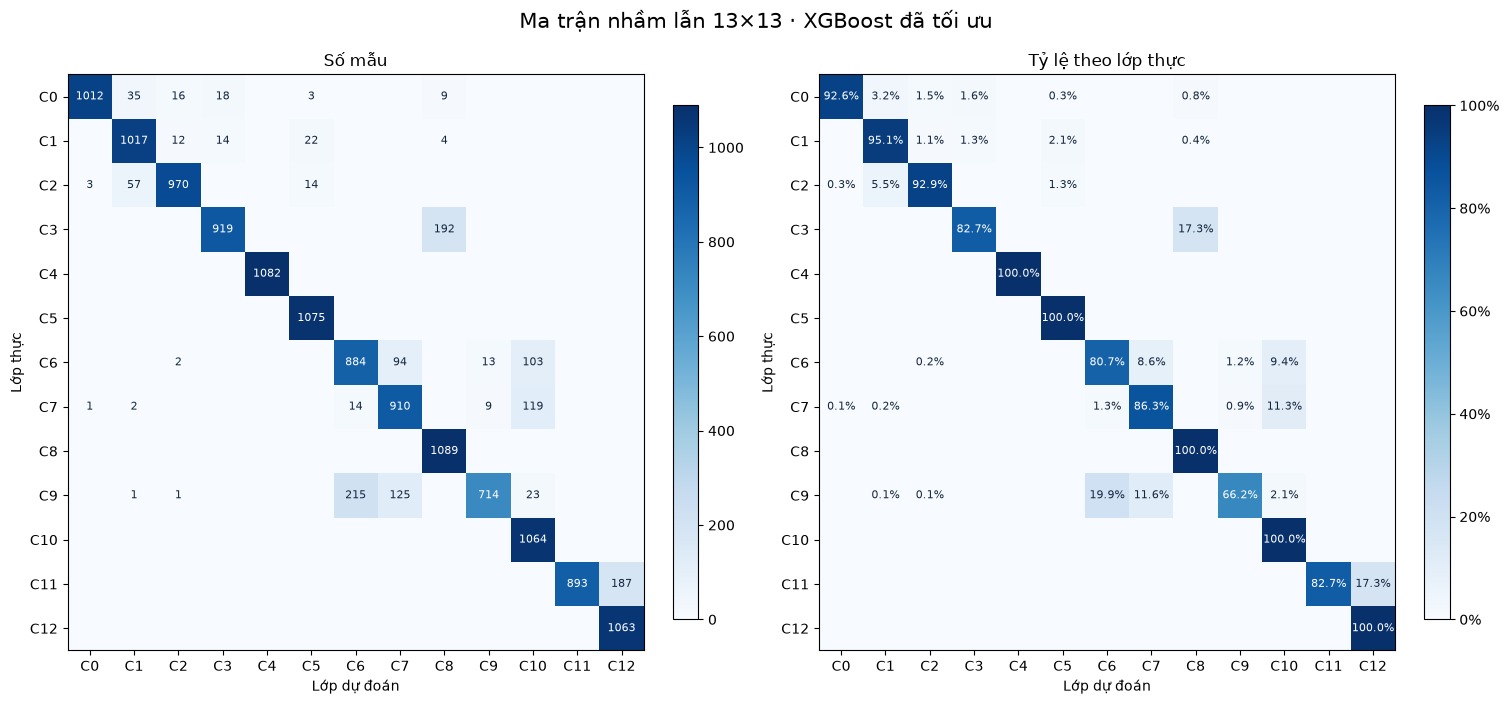

In [ ]:
from matplotlib.ticker import PercentFormatter

# Đối chiếu số mẫu và tỷ lệ của XGBoost đã tối ưu trên hai ma trận.
fig, axes = plt.subplots(1, 2, figsize=(15, 7), layout="constrained")
matrix_views = [
    ("counts", "Số mẫu", "d", None),
    ("normalized", "Tỷ lệ theo lớp thực", ".1%", 1),
]

for ax, (matrix_key, title, value_format, vmax) in zip(axes, matrix_views):
    matrix = tuned_test[matrix_key]
    heatmap = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=vmax)
    ax.set(
        title=title, xlabel="Lớp dự đoán", ylabel="Lớp thực",
        xticks=class_ids, yticks=class_ids,
        xticklabels=class_codes, yticklabels=class_codes,
    )
    for (row, col), value in np.ndenumerate(matrix):
        if value > 0:
            color = "white" if value > heatmap.norm.vmax / 2 else "#14263d"
            ax.text(col, row, format(value, value_format), ha="center", va="center",
                    color=color, fontsize=8)
    colorbar = fig.colorbar(heatmap, ax=ax, shrink=0.8)
    if matrix_key == "normalized":
        colorbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

fig.suptitle("Ma trận nhầm lẫn 13×13 · XGBoost đã tối ưu", fontsize=15)
plt.show()
plt.close(fig)

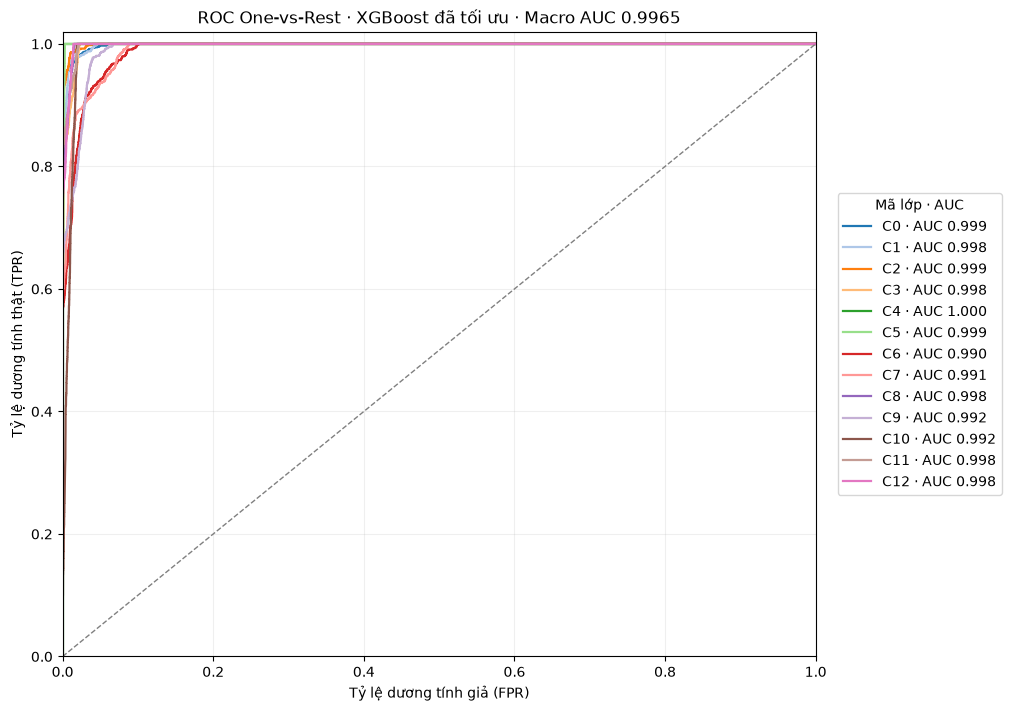

In [ ]:
# Vẽ một đường ROC cho mỗi lớp từ đúng cột xác suất của lớp đó.
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
colors = plt.get_cmap("tab20").colors
for class_id, class_code in zip(class_ids, class_codes):
    fpr, tpr, _ = roc_curve(y_test == class_id, tuned_test["y_proba"][:, class_id])
    auc_score = tuned_test["auc_by_class"][class_id]
    ax.plot(fpr, tpr, color=colors[class_id], linewidth=1.6,
            label=f"{class_code} · AUC {auc_score:.3f}")

ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
macro_auc = tuned_test["auc_by_class"].mean()
ax.set(
    xlabel="Tỷ lệ dương tính giả (FPR)",
    ylabel="Tỷ lệ dương tính thật (TPR)",
    title=f"ROC One-vs-Rest · XGBoost đã tối ưu · Macro AUC {macro_auc:.4f}",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.grid(alpha=0.2)
ax.legend(title="Mã lớp · AUC", loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()
plt.close(fig)

# 2.3. Giải thích mô hình XGBoost đa lớp

Dùng XGBoost đã chọn bằng CV ở mục 2.1. Feature Importance theo gain mô tả vai trò tổng thể của các đặc trưng. SHAP được tính trên 50 mẫu Test mỗi lớp, tổng cộng 650 mẫu, với thứ tự 35 cột sau mã hóa được giữ đúng theo Pipeline.

TreeExplainer dùng đầu ra raw và chế độ tree_path_dependent, lấy thống kê đường đi từ các cây đã học trên Train. Với mỗi lớp, tổng SHAP cộng giá trị nền bằng điểm margin trước softmax. SHAP dương đẩy điểm của lớp lên, SHAP âm kéo điểm xuống. Các đóng góp này giải thích hành vi của mô hình và cần được đối chiếu với ý nghĩa, nguồn gốc của các biến.

Các biểu đồ hiển thị giá trị số trước chuẩn hóa; các biến danh mục dùng mã số như phần tiền xử lý. Các cột one-hot của Urine Test được trình bày riêng. Tài liệu phương pháp [TreeExplainer](https://shap.readthedocs.io/en/stable/generated/shap.TreeExplainer.html).

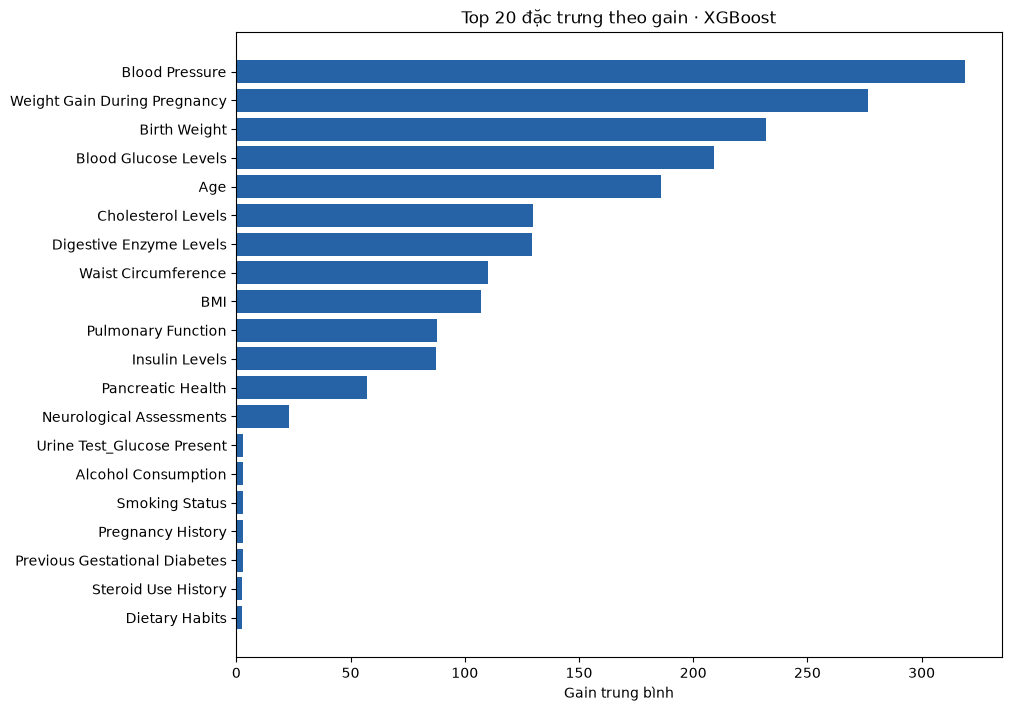

,feature,gain,gain_fraction
9,Blood Pressure,319.0874,0.1594
21,Weight Gain During Pregnancy,276.5104,0.1381
30,Birth Weight,232.0274,0.1159
12,Blood Glucose Levels,209.2488,0.1045
5,Age,185.7278,0.0928
10,Cholesterol Levels,129.7335,0.0648
29,Digestive Enzyme Levels,129.3948,0.0646
11,Waist Circumference,110.1519,0.0550
6,BMI,106.9008,0.0534
23,Pulmonary Function,87.9055,0.0439


In [ ]:


# Lấy đúng bộ tiền xử lý và bộ phân loại đã fit trong cùng một Pipeline.
explain_preprocessor = xgb_best.named_steps["preprocessor"]
explain_model = xgb_best.named_steps["classifier"]
feature_names = explain_preprocessor.feature_names_
np.testing.assert_array_equal(explain_model.classes_, np.arange(len(le.classes_)))

# Gain là mức cải thiện hàm mục tiêu trung bình ở các lần chia dùng đặc trưng.
gain_scores = explain_model.get_booster().get_score(importance_type="gain")
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "gain": [gain_scores.get(feature, 0.0) for feature in feature_names],
}).sort_values("gain", ascending=False)
assert feature_importance["gain"].sum() > 0
feature_importance["gain_fraction"] = feature_importance["gain"] / feature_importance["gain"].sum()

top_gain = feature_importance.head(20).sort_values("gain")
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.barh(top_gain["feature"], top_gain["gain"], color="#2563a6")
ax.set(xlabel="Gain trung bình", title="Top 20 đặc trưng theo gain · XGBoost")
plt.show()
plt.close(fig)
display(feature_importance.head(10).round(4))

In [ ]:
import shap
from scipy.special import softmax

# Lấy số mẫu bằng nhau cho mỗi lớp để tất cả 13 lớp được đại diện.
rng = np.random.default_rng(RANDOM_STATE)
shap_sample_positions = np.concatenate([
    rng.choice(np.flatnonzero(y_test == class_id),
               size=min(50, np.count_nonzero(y_test == class_id)), replace=False)
    for class_id in class_ids
])
X_shap_raw = X_test.iloc[shap_sample_positions]
X_shap = explain_preprocessor.transform(X_shap_raw)
X_shap_display = encode_features(X_shap_raw)[feature_names]

# Chế độ này dùng thống kê Train lưu trong cây và giải thích điểm trước softmax.
shap_explainer = shap.TreeExplainer(
    explain_model, model_output="raw", feature_perturbation="tree_path_dependent",
)
shap_explanation = shap_explainer(X_shap, check_additivity=True)
shap_values = shap_explanation.values
assert shap_values.shape == (len(X_shap), len(feature_names), len(class_ids))

# Kiểm tra tổng đóng góp khôi phục được margin, rồi khôi phục xác suất qua softmax.
shap_margins = shap_explanation.base_values + shap_values.sum(axis=1)
model_margins = explain_model.predict(X_shap, output_margin=True)
np.testing.assert_allclose(shap_margins, model_margins, atol=1e-4, rtol=1e-4)
np.testing.assert_allclose(softmax(shap_margins, axis=1),
                           xgb_best.predict_proba(X_shap_raw), atol=1e-5, rtol=1e-5)
print("Kích thước SHAP (mẫu, đặc trưng, lớp):", shap_values.shape)
print("Sai số cộng SHAP tối đa:", np.abs(shap_margins - model_margins).max())

Kích thước SHAP (mẫu, đặc trưng, lớp): (650, 35, 13)
Sai số cộng SHAP tối đa: 2.861023e-06


,class_code,class_name,rank,feature,mean_abs_shap
0,C0,Cystic Fibrosis-Related Diabetes (CFRD),1,Weight Gain During Pregnancy,0.9231
1,C0,Cystic Fibrosis-Related Diabetes (CFRD),2,Age,0.8226
2,C0,Cystic Fibrosis-Related Diabetes (CFRD),3,Insulin Levels,0.5619
3,C0,Cystic Fibrosis-Related Diabetes (CFRD),4,Pulmonary Function,0.3801
4,C0,Cystic Fibrosis-Related Diabetes (CFRD),5,Cholesterol Levels,0.3353
...,...,...,...,...,...
60,C12,Wolfram Syndrome,1,Birth Weight,1.6504
61,C12,Wolfram Syndrome,2,Blood Glucose Levels,0.9843
62,C12,Wolfram Syndrome,3,Age,0.3034
63,C12,Wolfram Syndrome,4,Insulin Levels,0.0790


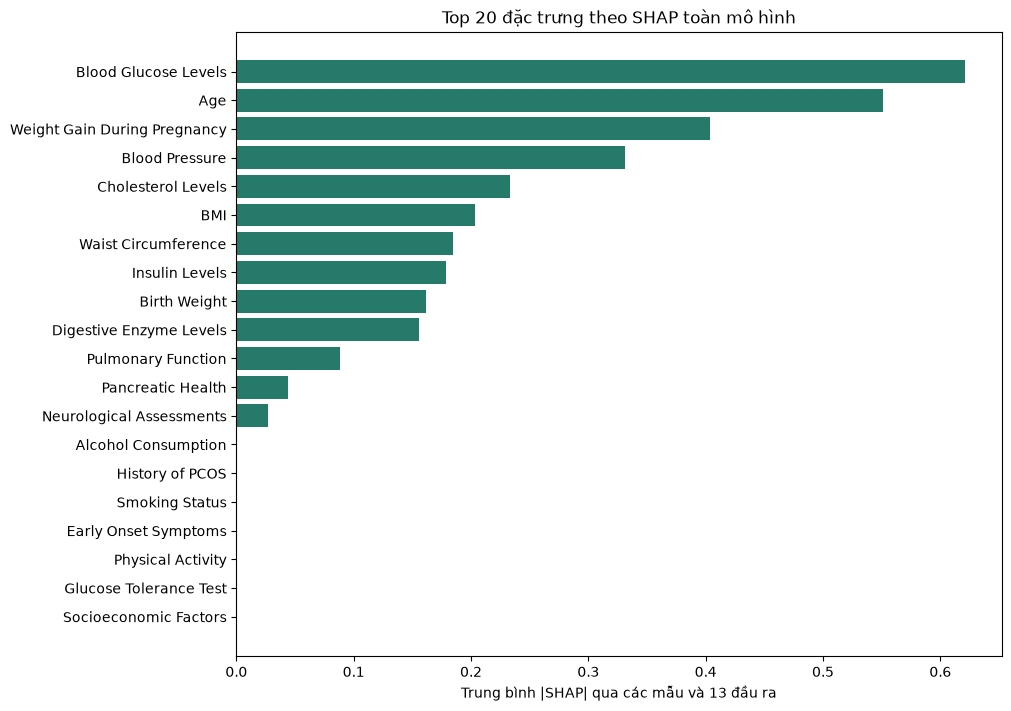

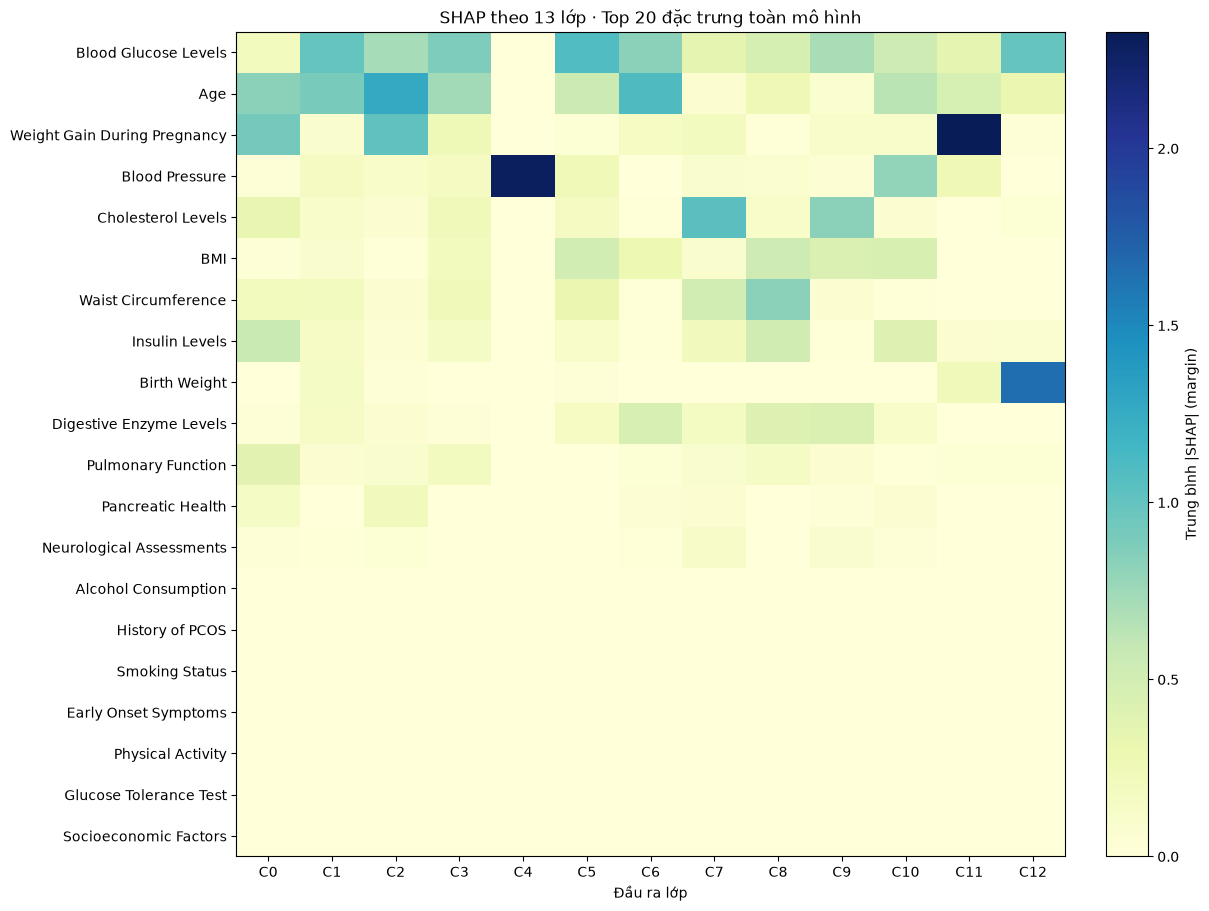

In [ ]:
# Mỗi cột là một đầu ra lớp; tính trung bình |SHAP| trên cùng 650 mẫu.
mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_by_class = pd.DataFrame(mean_abs_shap, index=feature_names, columns=class_codes)

shap_global = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs_shap.mean(axis=1),
}).sort_values("mean_abs_shap", ascending=False)

# Tổng hợp Top 5 đặc trưng cho đủ 13 lớp và ghi rõ tên lớp để đọc báo cáo.
top_features_by_class = []
for class_id, class_name in enumerate(le.classes_):
    top_features = shap_by_class[class_codes[class_id]].nlargest(5)
    top_features_by_class.append(pd.DataFrame({
        "class_code": class_codes[class_id],
        "class_name": class_name,
        "rank": np.arange(1, len(top_features) + 1),
        "feature": top_features.index,
        "mean_abs_shap": top_features.to_numpy(),
    }))
shap_top5 = pd.concat(top_features_by_class, ignore_index=True)
display(shap_top5.round(4))

top_global = shap_global.head(20).sort_values("mean_abs_shap")
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.barh(top_global["feature"], top_global["mean_abs_shap"], color="#257a69")
ax.set(xlabel="Trung bình |SHAP| qua các mẫu và 13 đầu ra",
       title="Top 20 đặc trưng theo SHAP toàn mô hình")
plt.show()
plt.close(fig)

# Heatmap giúp đối chiếu cùng một đặc trưng giữa các đầu ra bệnh.
heatmap_features = shap_global.head(20)["feature"]
fig, ax = plt.subplots(figsize=(12, 9), layout="constrained")
heatmap = ax.imshow(shap_by_class.loc[heatmap_features], aspect="auto", cmap="YlGnBu")
ax.set(xticks=class_ids, xticklabels=class_codes,
       yticks=np.arange(len(heatmap_features)), yticklabels=heatmap_features,
       xlabel="Đầu ra lớp", title="SHAP theo 13 lớp · Top 20 đặc trưng toàn mô hình")
fig.colorbar(heatmap, ax=ax, label="Trung bình |SHAP| (margin)")
plt.show()
plt.close(fig)

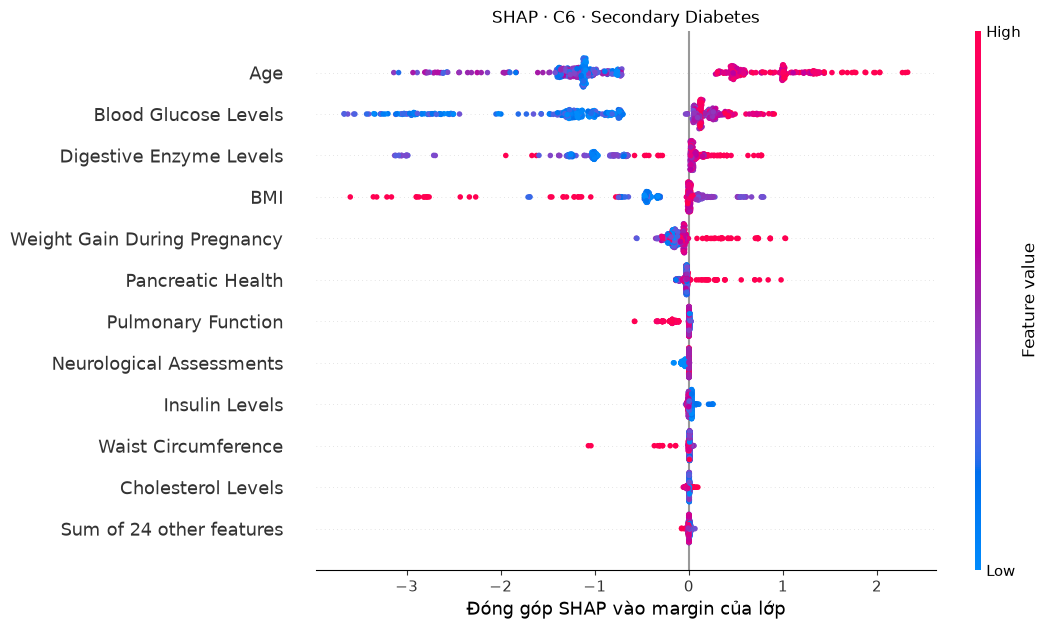

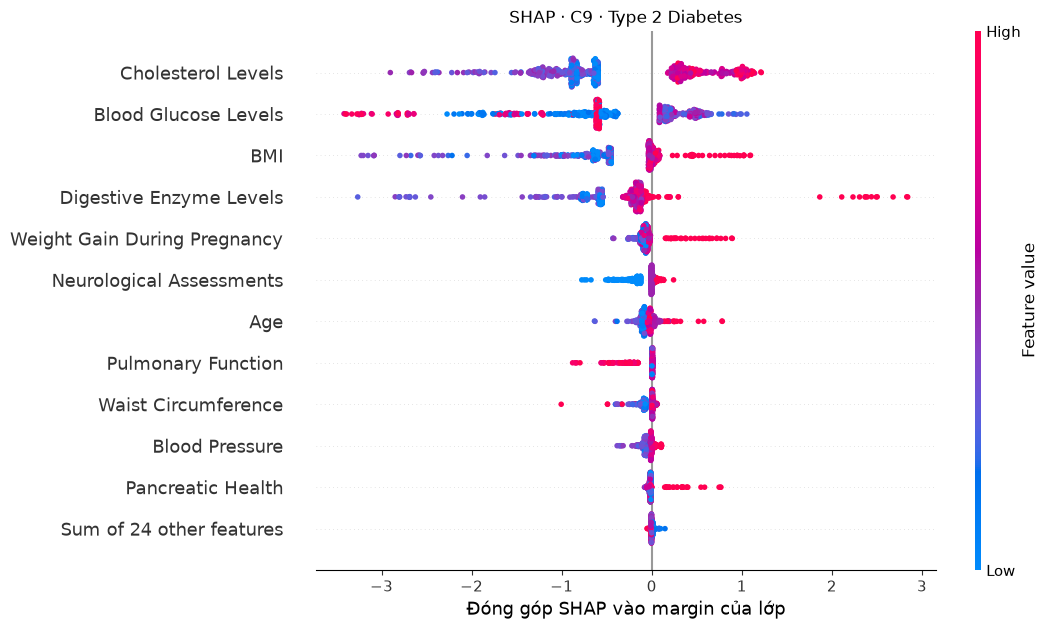

In [ ]:
# Tạo beeswarm cho đủ 13 lớp; hiển thị hai lớp cần phân tích lỗi ở mục 2.2.
for class_id, class_name in enumerate(le.classes_):
    class_explanation = shap.Explanation(
        values=shap_values[:, :, class_id],
        base_values=shap_explanation.base_values[:, class_id],
        data=X_shap_display.to_numpy(),
        feature_names=feature_names,
    )
    shap.plots.beeswarm(class_explanation, max_display=12, show=False, plot_size=(10, 7))
    fig = plt.gcf()
    plt.title(f"SHAP · {class_codes[class_id]} · {class_name}", fontsize=12)
    plt.xlabel("Đóng góp SHAP vào margin của lớp")
    if class_name in ("Type 2 Diabetes", "Secondary Diabetes"):
        plt.show()
    plt.close(fig)

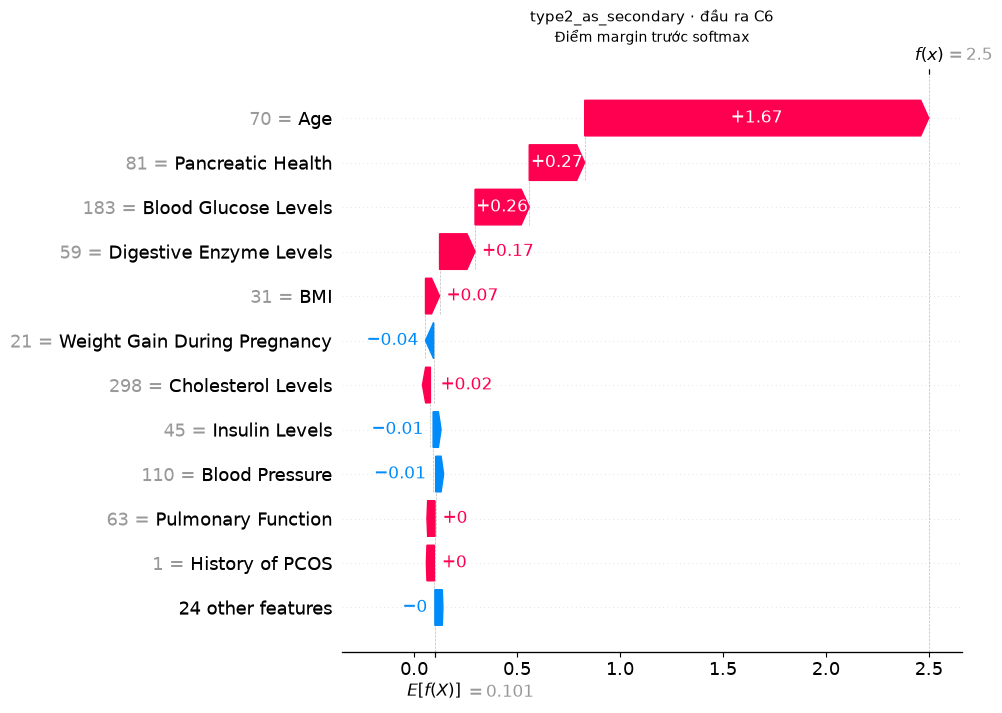

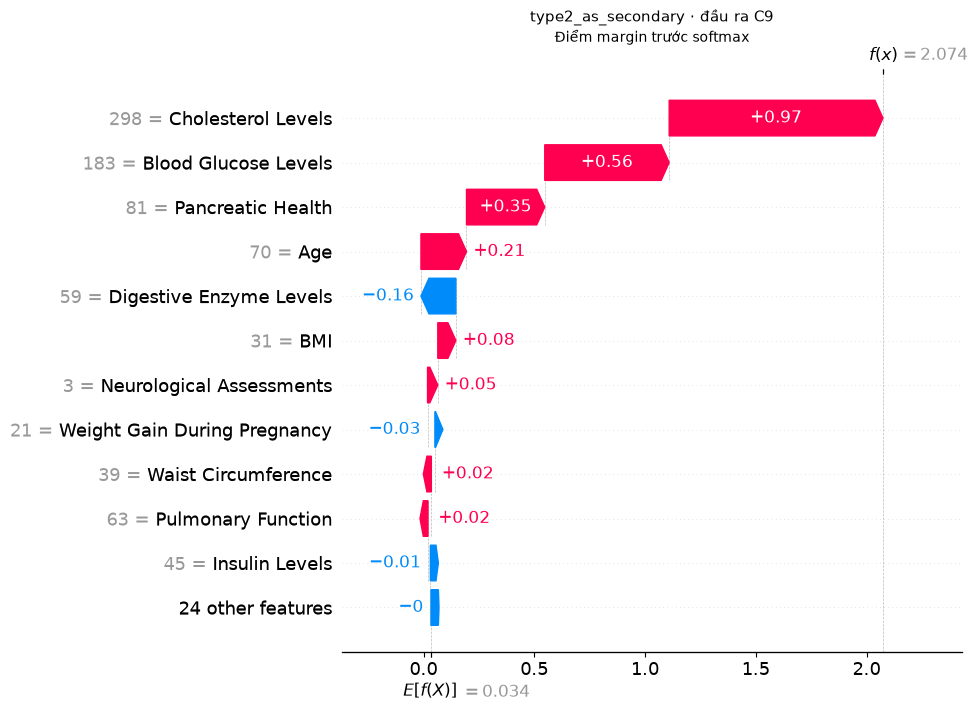

,case,dataset_row,true_class,predicted_class,probability_true_class,probability_predicted_class
0,type2_correct,46802,Type 2 Diabetes,Type 2 Diabetes,0.9693,0.9693
1,secondary_correct,22962,Secondary Diabetes,Secondary Diabetes,0.9810,0.9810
2,type2_as_secondary,64791,Type 2 Diabetes,Secondary Diabetes,0.3773,0.5776
3,type2_as_steroid,498,Type 2 Diabetes,Steroid-Induced Diabetes,0.2868,0.6320


In [ ]:
# Chọn mẫu đầu tiên thỏa điều kiện để người đọc có thể tái lập các ví dụ.
type2_id = int(le.transform(["Type 2 Diabetes"])[0])
secondary_id = int(le.transform(["Secondary Diabetes"])[0])
steroid_id = int(le.transform(["Steroid-Induced Diabetes"])[0])
case_definitions = [
    ("type2_correct", type2_id, type2_id),
    ("secondary_correct", secondary_id, secondary_id),
    ("type2_as_secondary", type2_id, secondary_id),
    ("type2_as_steroid", type2_id, steroid_id),
]

selected_cases = []
for case_name, true_class, predicted_class in case_definitions:
    positions = np.flatnonzero((y_test == true_class) & (tuned_test["y_pred"] == predicted_class))
    if positions.size:
        selected_cases.append((case_name, int(positions[0]), true_class, predicted_class))

case_positions = [position for _, position, _, _ in selected_cases]
X_cases_raw = X_test.iloc[case_positions]
X_cases = explain_preprocessor.transform(X_cases_raw)
X_cases_display = encode_features(X_cases_raw)[feature_names]
case_explanations = shap_explainer(X_cases, check_additivity=True)
case_summary_rows = []

for case_index, (case_name, test_position, true_class, predicted_class) in enumerate(selected_cases):
    case_summary_rows.append({
        "case": case_name,
        "dataset_row": X_test.index[test_position],
        "true_class": le.classes_[true_class],
        "predicted_class": le.classes_[predicted_class],
        "probability_true_class": tuned_test["y_proba"][test_position, true_class],
        "probability_predicted_class": tuned_test["y_proba"][test_position, predicted_class],
    })
    # Với mẫu sai, giải thích cả lớp dự đoán lẫn lớp thực để đối chiếu.
    for output_class in dict.fromkeys([predicted_class, true_class]):
        contributions = case_explanations.values[case_index, :, output_class]
        local_explanation = shap.Explanation(
            values=contributions,
            base_values=case_explanations.base_values[case_index, output_class],
            data=X_cases_display.iloc[case_index].to_numpy(),
            feature_names=feature_names,
        )
        shap.plots.waterfall(local_explanation, max_display=12, show=False)
        fig = plt.gcf()
        plt.title(f"{case_name} · đầu ra C{output_class}", fontsize=11)
        plt.xlabel("Điểm margin trước softmax")
        if case_name == "type2_as_secondary":
            plt.show()
        plt.close(fig)

case_summary = pd.DataFrame(case_summary_rows)
display(case_summary.round(4))


# 3. Benchmark hiệu năng và khả năng mở rộng

Mục này **kế thừa trực tiếp mục 1–2**: dữ liệu được mã hóa và chuẩn hóa bằng bộ tiền xử lý `pre` (`DiabetesPreprocessor`) của mục 1, còn XGBoost đơn luồng dùng siêu tham số `best_params` do `RandomizedSearchCV` chọn ở mục 2.1.

- **3.2:** so sánh 5 thuật toán trên đúng tập Train/Test 70.000 dòng của mục 1.
- **3.3–3.5:** so sánh XGBoost **đơn luồng** với XGBoost **phân tán (Dask)** trên dữ liệu 70.000, 250.000 và 500.000 dòng, đo thời gian huấn luyện và RAM.

Dask được chạy trên cụm cục bộ của máy hiện tại, không phải cụm nhiều máy độc lập.


## 3.1. Chuẩn bị môi trường đo

Cài thư viện đo RAM và xử lý phân tán. Nếu môi trường yêu cầu khởi động lại kernel, hãy khởi động lại rồi chạy notebook từ phần nạp dữ liệu.

In [ ]:
%pip install -q psutil pyarrow "dask[distributed,dataframe]"


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os, gc, time, atexit, logging, tempfile, threading, warnings
from contextlib import contextmanager

import psutil
import dask
import dask.array as da
from dask.distributed import Client, LocalCluster, wait
from xgboost import XGBClassifier
from xgboost import dask as dxgb

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score)

# Kiểm tra mục 1–2 đã chạy xong các biến mà mục 3 kế thừa.
# pre: bộ tiền xử lý ở mục 1 | best_params: siêu tham số XGBoost tối ưu ở mục 2.1
_required = ["df", "num_cols", "le", "pre", "X_train_p", "X_test_p",
             "y_train", "y_test", "RANDOM_STATE", "best_params"]
_missing = [name for name in _required if name not in globals()]
if _missing:
    raise RuntimeError(f"Hãy chạy mục 1 và 2 trước. Còn thiếu: {_missing}")

# Dask dùng thư mục tạm riêng; dữ liệu trung gian được xóa ở cuối mục 3.
BD_TMP = tempfile.TemporaryDirectory(prefix="bda_dask_")
atexit.register(BD_TMP.cleanup)
dask.config.set({
    "temporary-directory": BD_TMP.name,
    "distributed.worker.memory.target": 0.60,
    "distributed.worker.memory.spill": 0.70,
    "distributed.worker.memory.pause": 0.80,
    "distributed.worker.memory.terminate": 0.95,
})
logging.getLogger("distributed").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="distributed")

# Giữ nguyên ba quy mô yêu cầu; chỉ điều chỉnh số worker theo tài nguyên máy.
N_LOGICAL = os.cpu_count() or 2
N_PHYSICAL = psutil.cpu_count(logical=False) or N_LOGICAL
RAM_TOTAL_GB = psutil.virtual_memory().total / 2**30
RAM_AVAILABLE_GB = psutil.virtual_memory().available / 2**30
# Dùng tối đa 4 worker khi RAM còn đủ; máy ít RAM giới hạn ở 2 worker để tránh swap.
MAX_WORKERS_BY_RAM = 4 if RAM_AVAILABLE_GB >= 8 else 2
N_WORKERS = max(1, min(N_PHYSICAL, MAX_WORKERS_BY_RAM))
BENCH_SIZES = [70_000, 250_000, 500_000]

NOISE_FRAC = 0.05
SEED = RANDOM_STATE

# XGBoost phân tán: giữ nguyên cấu hình benchmark hiện tại.
XGB_ROUNDS, XGB_DEPTH, XGB_LR = 30, 5, 0.1
# XGBoost đơn luồng: kế thừa siêu tham số tối ưu của mục 2.1.
XGB_SEQ_PARAMS = dict(best_params)
# Đặt True nếu muốn bản phân tán cũng dùng đúng siêu tham số mục 2.1 (cùng khối lượng tính toán).
XGB_DASK_USE_SECTION2 = False

MODE_SEQ = "Đơn luồng"
MODE_DASK = "Phân tán"
MODES = [MODE_SEQ, MODE_DASK]

print(f"CPU: {N_PHYSICAL} lõi vật lý / {N_LOGICAL} luồng logic")
print(f"RAM tổng: {RAM_TOTAL_GB:.1f} GB | RAM còn trống: {RAM_AVAILABLE_GB:.1f} GB")
print(f"Dask workers: {N_WORKERS}")
print("Quy mô benchmark:", [f"{n:,}" for n in BENCH_SIZES])
print("XGBoost đơn luồng (kế thừa mục 2.1):", XGB_SEQ_PARAMS)
if XGB_DASK_USE_SECTION2:
    print("XGBoost phân tán: dùng cùng siêu tham số với đơn luồng")
else:
    print(f"XGBoost phân tán: {XGB_ROUNDS} vòng, depth={XGB_DEPTH}, lr={XGB_LR}")


CPU: 12 lõi vật lý / 16 luồng logic
RAM tổng: 15.6 GB | RAM còn trống: 4.2 GB
Dask workers: 2
Quy mô benchmark: ['70,000', '250,000', '500,000']
XGBoost đơn luồng (kế thừa mục 2.1): {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 8, 'learning_rate': 0.05}
XGBoost phân tán: 30 vòng, depth=5, lr=0.1


In [ ]:
class ResourceMonitor:
    """Đo RSS của tiến trình notebook và toàn bộ tiến trình con (worker Dask)."""

    def __init__(self, interval=0.05):
        self.interval = interval
        self._proc = psutil.Process(os.getpid())
        self._stop = threading.Event()
        self._thread = None
        self._base, self._pid_peak = {}, {}
        self.baseline_mb = 0.0
        self.peak_mb = 0.0

    def _snapshot(self):
        try:
            procs = [self._proc] + self._proc.children(recursive=True)
        except psutil.Error:
            procs = [self._proc]
        snap = {}
        for proc in procs:
            try:
                snap[proc.pid] = proc.memory_info().rss / 2**20
            except psutil.Error:
                pass
        return snap

    def _record(self):
        snap = self._snapshot()
        self.peak_mb = max(self.peak_mb, sum(snap.values()))
        for pid, mb in snap.items():
            self._pid_peak[pid] = max(self._pid_peak.get(pid, 0.0), mb)

    def _loop(self):
        while not self._stop.is_set():
            self._record()
            self._stop.wait(self.interval)

    def __enter__(self):
        gc.collect()
        self._base = self._snapshot()
        self._pid_peak = dict(self._base)
        self.baseline_mb = self.peak_mb = sum(self._base.values())
        self._stop.clear()
        self._thread = threading.Thread(target=self._loop, daemon=True)
        self._thread.start()
        return self

    def __exit__(self, *exc_info):
        self._stop.set()
        self._thread.join()
        self._record()
        return False

    @property
    def delta_mb(self):
        return max(self.peak_mb - self.baseline_mb, 0.0)

    @property
    def max_proc_mb(self):
        return max((max(mb - self._base.get(pid, 0.0), 0.0)
                    for pid, mb in self._pid_peak.items()), default=0.0)


@contextmanager
def dask_cluster():
    """Cụm Dask cục bộ, giới hạn số worker và mỗi worker một luồng."""
    global BD_TMP
    # Nếu người dùng chạy lại benchmark sau ô dọn dẹp, tạo lại thư mục tạm.
    if not os.path.isdir(BD_TMP.name):
        BD_TMP = tempfile.TemporaryDirectory(prefix="bda_dask_")
        atexit.register(BD_TMP.cleanup)
        dask.config.set({"temporary-directory": BD_TMP.name})
    available_bytes = psutil.virtual_memory().available
    worker_memory_limit = max(512 * 2**20, int(available_bytes * 0.60 / N_WORKERS))
    cluster = LocalCluster(n_workers=N_WORKERS, threads_per_worker=1, processes=True,
                           dashboard_address=None, silence_logs=logging.ERROR,
                           memory_limit=worker_memory_limit)
    client = Client(cluster)
    try:
        yield client
    finally:
        client.close()
        cluster.close()


def size_label(n):
    return f"{n/1_000_000:g}M" if n >= 1_000_000 else f"{n/1000:g}k"


# Kiểm tra nhanh bộ đo RAM với vùng nhớ khoảng 95 MB.
with ResourceMonitor() as _mon:
    _tmp = np.ones((12_500_000,), dtype=np.float64)
    time.sleep(0.15)
print(f"Bộ đo RAM hoạt động: tăng {_mon.delta_mb:.0f} MB (kỳ vọng xấp xỉ 95 MB)")
del _tmp, _mon
gc.collect()


Bộ đo RAM hoạt động: tăng 95 MB (kỳ vọng xấp xỉ 95 MB)


0

## 3.2. So sánh 5 thuật toán phân loại

Năm thuật toán được huấn luyện và đánh giá trên cùng tập Train/Test 70.000 dòng đã tiền xử lý ở mục 1: Logistic Regression, Decision Tree, Random Forest, HistGradientBoosting và XGBoost (siêu tham số từ mục 2.1). Bảng bên dưới trình bày các chỉ số chất lượng, thời gian huấn luyện/dự đoán và RAM tăng thêm. Bốn biểu đồ tiếp theo đối chiếu trực quan **thời gian huấn luyện**, **thời gian dự đoán**, **dung lượng RAM** và **độ chính xác (Accuracy)** giữa các mô hình.

*Lưu ý: “Dung lượng” trong phần so sánh mô hình được thể hiện bằng lượng RAM tăng thêm khi chạy mô hình (MB).*


Siêu tham số XGBoost dùng để so sánh: {'learning_rate': 0.05, 'max_depth': 8, 'subsample': 0.8, 'n_estimators': 100}
Đang huấn luyện: Logistic Regression ...
Đang huấn luyện: Decision Tree ...
Đang huấn luyện: Random Forest ...
Đang huấn luyện: HistGradientBoosting ...
Đang huấn luyện: XGBoost (đã tối ưu) ...


,Mô hình,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC (OvR),Thời gian huấn luyện (s),Thời gian dự đoán (s),RAM tăng thêm (MB)
Hạng,,,,,,,,,,
1,XGBoost (đã tối ưu),0.9072,0.9153,0.9077,0.9061,0.9060,0.9965,8.6745,0.1156,14.3008
2,Random Forest,0.9021,0.9082,0.9025,0.9010,0.9009,0.9955,4.8048,0.3036,207.6016
3,HistGradientBoosting,0.9004,0.9014,0.9006,0.8996,0.8995,0.9963,72.0511,1.3350,28.5195
4,Decision Tree,0.8001,0.8497,0.8000,0.7993,0.7996,0.9775,0.7924,0.0097,7.6641
5,Logistic Regression,0.7561,0.7552,0.7558,0.7552,0.7556,0.9818,25.6187,0.0176,26.1367


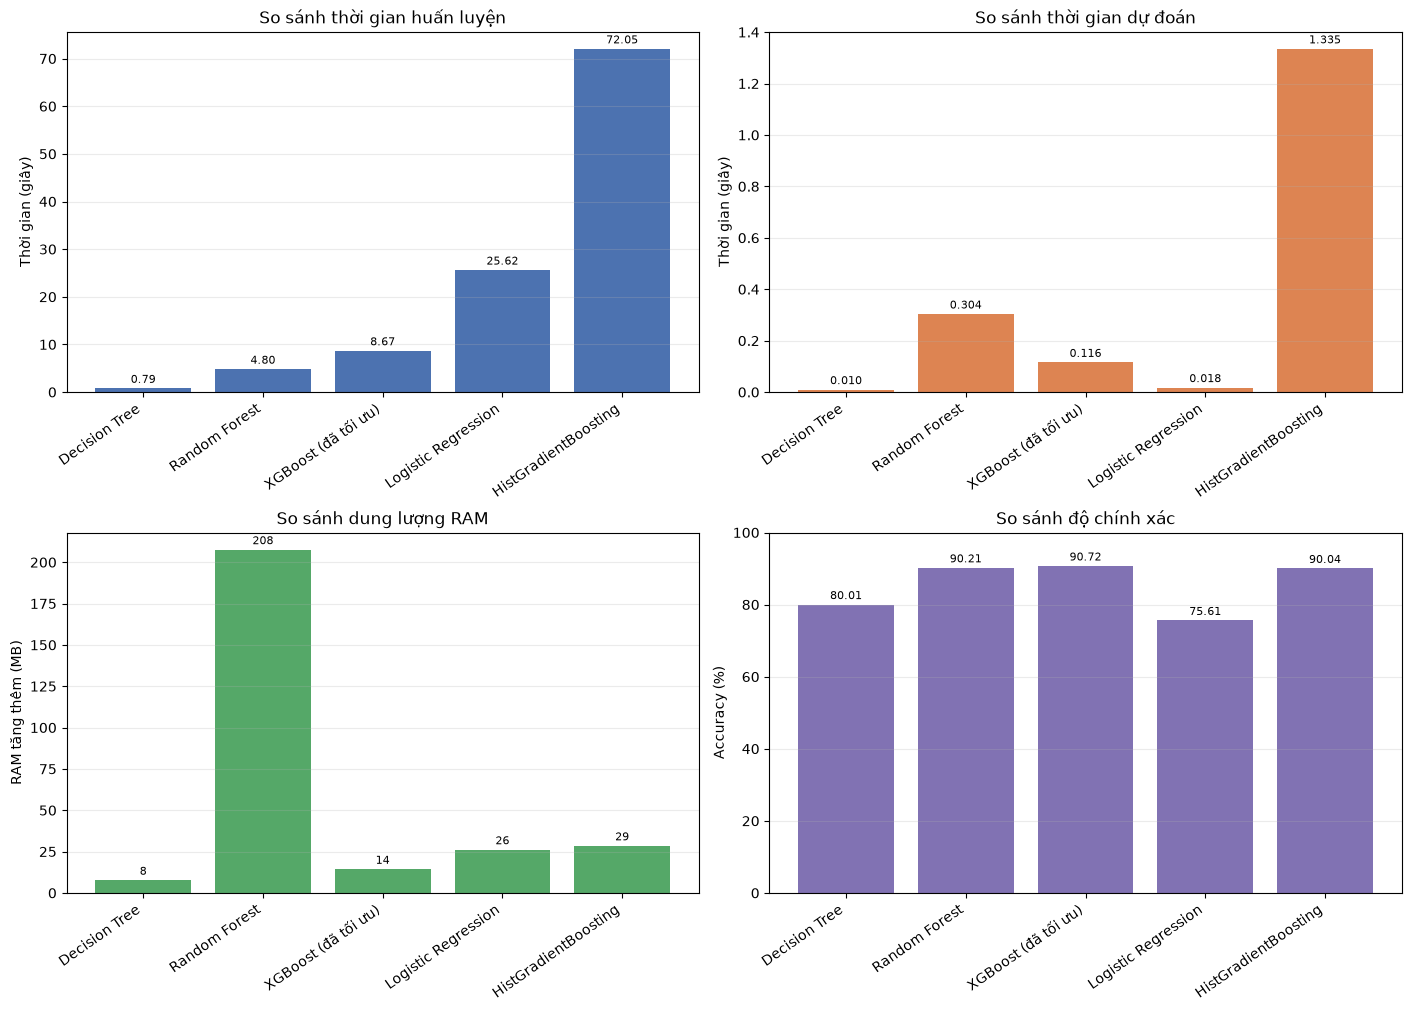

In [ ]:
# Siêu tham số XGBoost: lấy kết quả RandomizedSearchCV ở mục 2.1, nếu chưa chạy thì dùng mặc định.
xgb_params = dict(learning_rate=0.1, max_depth=4, subsample=1.0, n_estimators=100)
if "best_params" in globals():
    xgb_params.update(best_params)
print("Siêu tham số XGBoost dùng để so sánh:", xgb_params)

five_class_ids = np.arange(len(le.classes_))


def build_five_models():
    return {
        "Logistic Regression": LogisticRegression(solver="lbfgs", max_iter=1000),
        "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=16, n_jobs=-1, random_state=RANDOM_STATE),
        "HistGradientBoosting": HistGradientBoostingClassifier(
            max_iter=200, learning_rate=0.1, max_depth=6, early_stopping=False,
            random_state=RANDOM_STATE),
        "XGBoost (đã tối ưu)": XGBClassifier(
            objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
            n_jobs=-1, random_state=RANDOM_STATE, **xgb_params),
    }


five_rows, five_f1_by_class = [], {}
for five_name, five_model in build_five_models().items():
    print(f"Đang huấn luyện: {five_name} ...", flush=True)
    with ResourceMonitor() as five_mon:
        t0 = time.perf_counter()
        five_model.fit(X_train_p, y_train)
        five_fit_s = time.perf_counter() - t0
        t0 = time.perf_counter()
        five_proba = five_model.predict_proba(X_test_p)
        five_pred_s = time.perf_counter() - t0

    np.testing.assert_array_equal(five_model.classes_, five_class_ids)
    five_proba = five_proba / five_proba.sum(axis=1, keepdims=True)   # đảm bảo tổng xác suất = 1
    five_pred = five_proba.argmax(axis=1)
    five_f1_by_class[five_name] = f1_score(y_test, five_pred, labels=five_class_ids,
                                           average=None, zero_division=0)
    five_rows.append({
        "Mô hình": five_name,
        "Accuracy": accuracy_score(y_test, five_pred),
        "Macro Precision": precision_score(y_test, five_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, five_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, five_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, five_pred, average="weighted", zero_division=0),
        "Macro ROC-AUC (OvR)": roc_auc_score(y_test, five_proba, multi_class="ovr",
                                             average="macro", labels=five_class_ids),
        "Thời gian huấn luyện (s)": five_fit_s,
        "Thời gian dự đoán (s)": five_pred_s,
        "RAM tăng thêm (MB)": five_mon.delta_mb,
    })

five_summary = (pd.DataFrame(five_rows).sort_values("Macro F1", ascending=False)
                .reset_index(drop=True))
five_summary.index = five_summary.index + 1
five_summary.index.name = "Hạng"
display(five_summary.round(4))

# Biểu đồ so sánh 5 mô hình: thời gian huấn luyện, thời gian dự đoán, RAM và độ chính xác.
chart_df = five_summary.sort_values("Thời gian huấn luyện (s)", ascending=True)
model_labels = chart_df["Mô hình"].tolist()
x = np.arange(len(model_labels))

fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout="constrained")

# Biểu đồ 1: thời gian huấn luyện.
bars = axes[0, 0].bar(x, chart_df["Thời gian huấn luyện (s)"], color="#4c72b0")
axes[0, 0].bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
axes[0, 0].set_title("So sánh thời gian huấn luyện")
axes[0, 0].set_ylabel("Thời gian (giây)")

# Biểu đồ 2: thời gian dự đoán trên tập Test.
bars = axes[0, 1].bar(x, chart_df["Thời gian dự đoán (s)"], color="#dd8452")
axes[0, 1].bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
axes[0, 1].set_title("So sánh thời gian dự đoán")
axes[0, 1].set_ylabel("Thời gian (giây)")

# Biểu đồ 3: RAM tăng thêm trong quá trình chạy.
bars = axes[1, 0].bar(x, chart_df["RAM tăng thêm (MB)"], color="#55a868")
axes[1, 0].bar_label(bars, fmt="%.0f", fontsize=8, padding=2)
axes[1, 0].set_title("So sánh dung lượng RAM")
axes[1, 0].set_ylabel("RAM tăng thêm (MB)")

# Biểu đồ 4: độ chính xác của từng mô hình.
bars = axes[1, 1].bar(x, chart_df["Accuracy"] * 100, color="#8172b3")
axes[1, 1].bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
axes[1, 1].set_title("So sánh độ chính xác")
axes[1, 1].set_ylabel("Accuracy (%)")
axes[1, 1].set_ylim(0, 100)

for ax in axes.ravel():
    ax.set_xticks(x, model_labels, rotation=35, ha="right")
    ax.grid(axis="y", alpha=0.25)

plt.show()


## 3.3. Sinh dữ liệu benchmark có kiểm soát

Dữ liệu gốc 70.000 dòng được mã hóa và chuẩn hóa bằng đúng bộ tiền xử lý `pre` của mục 1 (35 đặc trưng; 13 biến số đã z-score theo thống kê của tập Train), sau đó nhân bản tuần hoàn để tạo các quy mô **70.000, 250.000 và 500.000 dòng**. Tỷ lệ 13 lớp được giữ nguyên; chỉ 13 biến số được cộng nhiễu Gaussian nhẹ (5% độ lệch chuẩn), còn biến nhị phân, thứ bậc và one-hot được giữ nguyên.

Dữ liệu benchmark chỉ nằm trong RAM hoặc thư mục tạm của Dask, không xuất thành file kết quả.


In [ ]:
# Dùng chính bộ tiền xử lý đã fit ở mục 1 (mã hóa + chuẩn hóa), không tự chuẩn hóa lại.
bd_X_df = pre.transform(df.drop(columns="Target"))
bd_feature_names = list(bd_X_df.columns)
bd_base_X = bd_X_df.to_numpy(dtype=np.float32)
bd_base_y = le.transform(df["Target"]).astype(np.int64)
bd_num_idx = np.array([bd_feature_names.index(c) for c in num_cols])
bd_noise_std = (NOISE_FRAC * bd_base_X[:, bd_num_idx].std(axis=0)).astype(np.float32)
BD_N_FEATURES = bd_base_X.shape[1]
del bd_X_df


def make_chunk(base_X, base_y, start, stop, num_idx, noise_std, seed, block=10_000):
    """Sinh các dòng [start, stop) của bộ dữ liệu nhân bản.

    Dòng i lấy từ dòng (i mod n_gốc) của dữ liệu gốc. Các dòng thuộc lần nhân bản thứ hai
    trở đi được cộng nhiễu Gaussian lên các cột số. Nhiễu sinh theo từng khối cố định
    `block` dòng với hạt ngẫu nhiên riêng, nên kết quả không phụ thuộc cách chia khối.
    """
    n_base = len(base_X)
    rows = np.arange(start, stop)
    X = base_X[rows % n_base].copy()
    y = base_y[rows % n_base]
    if stop > n_base:
        for b in range(start // block, (stop - 1) // block + 1):
            lo, hi = max(b * block, start), min((b + 1) * block, stop)
            rng = np.random.default_rng([seed, b])
            noise = rng.normal(0.0, 1.0, size=(block, len(num_idx))).astype(np.float32) * noise_std
            local = np.arange(lo, hi)
            keep = local >= n_base                              # chỉ nhiễu phần đã nhân bản
            X[np.ix_(local[keep] - start, num_idx)] += noise[local[keep] - b * block]
    return X, y


def build_local(n_rows, chunk_rows=100_000):
    """Dữ liệu nằm trọn trong RAM của một tiến trình (mô hình đơn máy)."""
    X = np.empty((n_rows, BD_N_FEATURES), dtype=np.float32)
    y = np.empty(n_rows, dtype=np.int64)
    for start in range(0, n_rows, chunk_rows):
        stop = min(start + chunk_rows, n_rows)
        X[start:stop], y[start:stop] = make_chunk(
            bd_base_X, bd_base_y, start, stop, bd_num_idx, bd_noise_std, SEED)
    return X, y


def build_dask(client, n_rows):
    """Dữ liệu được chia khối và sinh ngay trên các worker, máy chủ không giữ bản đầy đủ."""
    n_chunks = N_WORKERS * 2
    bounds = np.linspace(0, n_rows, n_chunks + 1).astype(int)
    bx, by = dask.delayed(bd_base_X), dask.delayed(bd_base_y)
    xs, ys = [], []
    for start, stop in zip(bounds[:-1], bounds[1:]):
        part = dask.delayed(make_chunk, nout=2)(
            bx, by, int(start), int(stop), bd_num_idx, bd_noise_std, SEED)
        xs.append(da.from_delayed(part[0], shape=(int(stop - start), BD_N_FEATURES), dtype=np.float32))
        ys.append(da.from_delayed(part[1], shape=(int(stop - start),), dtype=np.int64))
    X, y = client.persist([da.concatenate(xs, axis=0), da.concatenate(ys, axis=0)])
    wait([X, y])
    return X, y


# Kiểm tra tính đúng đắn của bộ sinh dữ liệu.
chk_X, chk_y = build_local(2 * len(bd_base_X) + 123)
n0 = len(bd_base_X)
assert np.array_equal(chk_X[:n0], bd_base_X) and np.array_equal(chk_y[:n0], bd_base_y)   # bản gốc
assert np.array_equal(chk_y[n0:2 * n0], bd_base_y)                                       # nhãn giữ nguyên
bin_idx = [i for i in range(BD_N_FEATURES) if i not in set(bd_num_idx)]
assert np.array_equal(chk_X[n0:2 * n0][:, bin_idx], bd_base_X[:, bin_idx])               # cột nhị phân không nhiễu
assert not np.array_equal(chk_X[n0:2 * n0][:, bd_num_idx], bd_base_X[:, bd_num_idx])     # cột số có nhiễu
rel = np.abs(chk_X[n0:2 * n0][:, bd_num_idx] - bd_base_X[:, bd_num_idx]).mean(axis=0) / bd_base_X[:, bd_num_idx].std(axis=0)
print(f"Số đặc trưng: {BD_N_FEATURES} | Số cột số bị nhiễu: {len(bd_num_idx)}")
print(f"Độ lệch tuyệt đối trung bình do nhiễu: {rel.mean():.3f} × std (kỳ vọng ≈ {NOISE_FRAC * 0.8:.3f})")
print("Dung lượng ma trận X (float32):",
      {size_label(n): f"{n * BD_N_FEATURES * 4 / 2**20:.2f} MB" for n in BENCH_SIZES})
# Dữ liệu sinh trên máy đơn và sinh phân tán phải trùng khớp từng giá trị.
with dask_cluster() as chk_client:
    chk_n = n0 + 30_000
    dX, dy = build_dask(chk_client, chk_n)
    lX, ly = build_local(chk_n)
    assert np.array_equal(dX.compute(), lX) and np.array_equal(dy.compute(), ly)
print("Dữ liệu sinh phân tán trùng khớp với dữ liệu sinh trên một máy: OK")
del dX, dy, lX, ly
del chk_X, chk_y

Số đặc trưng: 35 | Số cột số bị nhiễu: 13
Độ lệch tuyệt đối trung bình do nhiễu: 0.040 × std (kỳ vọng ≈ 0.040)
Dung lượng ma trận X (float32): {'70k': '9.35 MB', '250k': '33.38 MB', '500k': '66.76 MB'}
Dữ liệu sinh phân tán trùng khớp với dữ liệu sinh trên một máy: OK


## 3.4. Thực nghiệm đơn luồng và phân tán (XGBoost)

| Chế độ | Cách thực hiện |
|---|---|
| Đơn luồng | `XGBClassifier(n_jobs=1)` với thuật toán và siêu tham số `best_params` đã chọn ở mục 2.1; dữ liệu nằm trọn trong một tiến trình |
| Phân tán | `DaskXGBClassifier`, dữ liệu chia khối và sinh ngay trên các Dask worker; giữ nguyên cấu hình benchmark (30 vòng, sâu 5, learning rate 0,1) |

Thời gian đo tập trung vào huấn luyện; sinh dữ liệu và khởi tạo cụm được tách riêng. Dữ liệu đầu vào đã được chuẩn hóa ở 3.3 theo đúng bộ tiền xử lý của mục 1 nên không còn giai đoạn chuẩn hóa riêng. Dask chạy trên cụm cục bộ của một máy, không phải cụm nhiều máy độc lập.

**Lưu ý khi đọc kết quả:** theo cấu hình mặc định, hai chế độ dùng siêu tham số khác nhau (mục 2.1 so với 30 vòng/sâu 5), nên khối lượng tính toán không hoàn toàn tương đương và Speedup chỉ mang tính tham khảo. Đặt `XGB_DASK_USE_SECTION2 = True` ở 3.1 để hai chế độ dùng cùng siêu tham số. Song song hóa có lợi khi dữ liệu đủ lớn; với dữ liệu nhỏ, chi phí điều phối có thể khiến chế độ phân tán chậm hơn, và notebook báo cáo đúng thời gian đo thực tế.


In [ ]:
# ---------- XGBoost ----------
# Đơn luồng: thuật toán và siêu tham số kế thừa từ mục 2.1 (RandomizedSearchCV).
XGB_SEQ_KW = dict(
    objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
    random_state=RANDOM_STATE, n_jobs=1, **XGB_SEQ_PARAMS,
)

# Phân tán: giữ nguyên cấu hình benchmark hiện tại (trừ khi bật XGB_DASK_USE_SECTION2).
if XGB_DASK_USE_SECTION2:
    XGB_DASK_KW = dict(
        objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
        random_state=SEED, **XGB_SEQ_PARAMS,
    )
else:
    XGB_DASK_KW = dict(
        objective="multi:softprob", tree_method="hist", n_estimators=XGB_ROUNDS,
        max_depth=XGB_DEPTH, learning_rate=XGB_LR, max_bin=128, random_state=SEED,
    )


def run_xgb_local(n):
    X, y = build_local(n)
    model = XGBClassifier(**XGB_SEQ_KW)
    t0 = time.perf_counter()
    model.fit(X, y)
    return time.perf_counter() - t0


def run_xgb_dask(n):
    with dask_cluster() as client:
        X, y = build_dask(client, n)
        model = dxgb.DaskXGBClassifier(n_jobs=1, **XGB_DASK_KW)
        model.client = client
        t0 = time.perf_counter()
        model.fit(X, y)
        return time.perf_counter() - t0


STAGES = {"xgb": "Huấn luyện XGBoost"}
RUNNERS = {
    ("xgb", MODE_SEQ): run_xgb_local,
    ("xgb", MODE_DASK): run_xgb_dask,
}


def bench_case(stage, mode, n):
    row = {
        "stage": stage, "mode": mode, "n_rows": n,
        "data_mb": n * BD_N_FEATURES * 4 / 2**20,
        "time_s": np.nan, "peak_mb": np.nan, "delta_mb": np.nan,
        "max_proc_mb": np.nan, "status": "ok",
    }
    gc.collect()
    with ResourceMonitor() as mon:
        try:
            row["time_s"] = RUNNERS[(stage, mode)](n)
        except MemoryError:
            row["status"] = "lỗi: hết RAM"
        except Exception as exc:
            row["status"] = f"lỗi: {type(exc).__name__}: {str(exc)[:160]}"
    row["peak_mb"] = mon.peak_mb
    row["delta_mb"] = mon.delta_mb
    row["max_proc_mb"] = mon.max_proc_mb
    gc.collect()
    return row


In [ ]:
# Chạy theo cấu hình hiện tại; nếu cell bị ngắt, chạy lại sẽ tiếp tục các ca đã thành công.
BD_CONFIG = {
    "sizes": tuple(BENCH_SIZES), "workers": N_WORKERS,
    "xgb_seq": tuple(sorted(XGB_SEQ_KW.items())),
    "xgb_dask": tuple(sorted(XGB_DASK_KW.items())),
}
if globals().get("BD_CONFIG_PREVIOUS") != BD_CONFIG:
    bd_rows = []
    BD_CONFIG_PREVIOUS = BD_CONFIG.copy()
elif "bd_rows" not in globals():
    bd_rows = []

t_start = time.perf_counter()
for n_rows in BENCH_SIZES:
    for stage in STAGES:
        for mode in MODES:
            if any(r["stage"] == stage and r["mode"] == mode and r["n_rows"] == n_rows
                   and r["status"] == "ok" for r in bd_rows):
                continue
            print(f"[{time.strftime('%H:%M:%S')}] {n_rows:>9,} dòng | {stage:<8} | {mode} ...",
                  end=" ", flush=True)
            result = bench_case(stage, mode, n_rows)
            bd_rows = [r for r in bd_rows if not (
                r["stage"] == stage and r["mode"] == mode and r["n_rows"] == n_rows
            )]
            bd_rows.append(result)
            if result["status"] == "ok":
                print(f"{result['time_s']:8.2f} s | RAM tăng {result['delta_mb']:7.0f} MB "
                      f"| tối đa/tiến trình {result['max_proc_mb']:7.0f} MB")
            else:
                print(result["status"])
print(f"Tổng thời gian thực nghiệm: {(time.perf_counter() - t_start) / 60:.1f} phút")

[16:24:16]    70,000 dòng | xgb      | Đơn luồng ...    32.12 s | RAM tăng      31 MB | tối đa/tiến trình      31 MB
[16:24:49]    70,000 dòng | xgb      | Phân tán ...     7.89 s | RAM tăng     490 MB | tối đa/tiến trình     244 MB
[16:25:01]   250,000 dòng | xgb      | Đơn luồng ...   131.63 s | RAM tăng     122 MB | tối đa/tiến trình     122 MB
[16:27:13]   250,000 dòng | xgb      | Phân tán ...    10.08 s | RAM tăng     570 MB | tối đa/tiến trình     284 MB
[16:27:26]   500,000 dòng | xgb      | Đơn luồng ...   236.87 s | RAM tăng     209 MB | tối đa/tiến trình     209 MB
[16:31:24]   500,000 dòng | xgb      | Phân tán ...    33.07 s | RAM tăng     675 MB | tối đa/tiến trình     337 MB
Tổng thời gian thực nghiệm: 7.7 phút


## 3.5. Bảng và biểu đồ tổng hợp kết quả

Bảng dưới đây tổng hợp thời gian huấn luyện, Speedup và RAM của XGBoost theo từng quy mô dữ liệu và hai chế độ xử lý. Speedup được tính bằng thời gian đơn luồng chia cho thời gian phân tán; giá trị lớn hơn 1 nghĩa là phân tán nhanh hơn, nhỏ hơn 1 nghĩa là đơn luồng nhanh hơn. Biểu đồ phía dưới so sánh **thời gian huấn luyện theo dung lượng dữ liệu (MB)**.


Cấu hình đo: 2 worker Dask | quy mô 70,000, 250,000, 500,000 dòng
Đơn luồng: {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 8, 'learning_rate': 0.05}
Phân tán : {'n_estimators': 30, 'max_depth': 5, 'learning_rate': 0.1}


,Giai đoạn,Số dòng,Chế độ,Dung lượng X (MB),Thời gian (giây),Speedup (lần),RAM tăng thêm (MB),RAM tăng tối đa/tiến trình (MB)
0,Huấn luyện XGBoost,70000,Đơn luồng,9.35,32.12,1.00,31.07,31.07
1,Huấn luyện XGBoost,70000,Phân tán,9.35,7.89,4.07,490.47,244.50
2,Huấn luyện XGBoost,250000,Đơn luồng,33.38,131.63,1.00,121.72,121.72
3,Huấn luyện XGBoost,250000,Phân tán,33.38,10.08,13.05,569.99,284.48
4,Huấn luyện XGBoost,500000,Đơn luồng,66.76,236.87,1.00,208.87,208.87
5,Huấn luyện XGBoost,500000,Phân tán,66.76,33.07,7.16,674.63,336.62


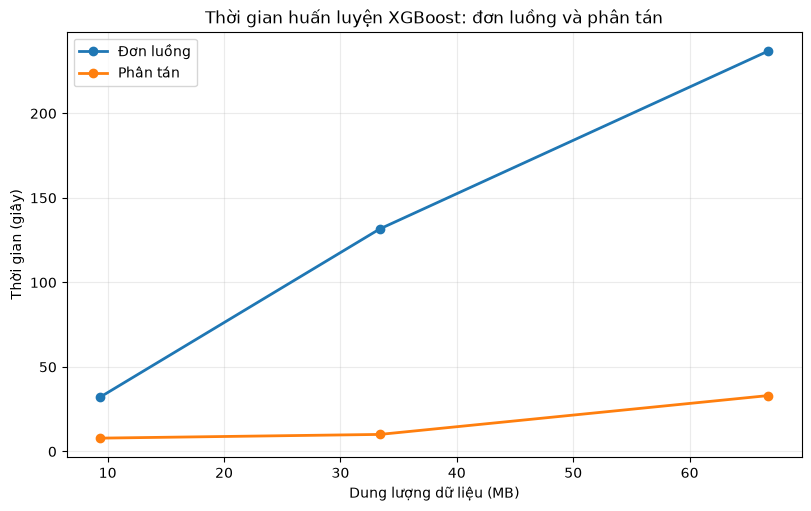

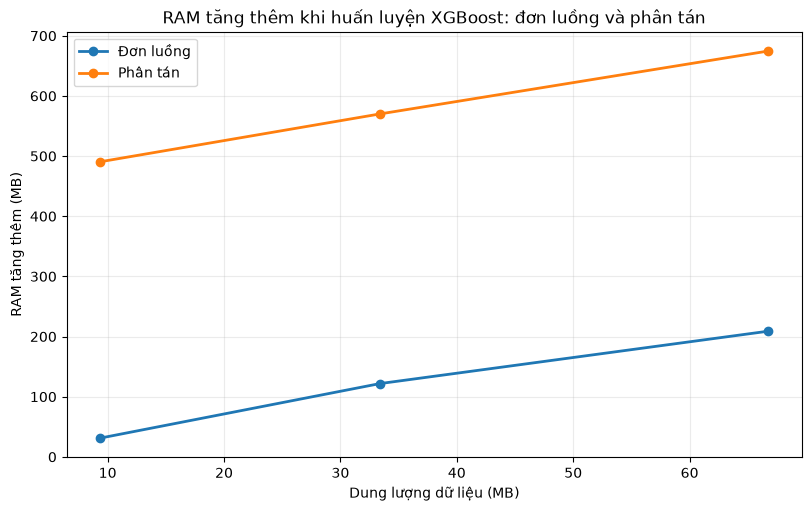

In [ ]:
bd_df = pd.DataFrame(bd_rows)
bd_ok = bd_df[bd_df["status"] == "ok"].copy()
if bd_ok.empty:
    raise RuntimeError("Chưa có phép đo thành công. Hãy kiểm tra lỗi ở ô 3.4 và chạy lại.")

# Tính Speedup so với ca tuần tự cùng giai đoạn và cùng số dòng.
seq_time = (bd_ok[bd_ok["mode"] == MODE_SEQ]
            .set_index(["stage", "n_rows"])["time_s"])
bd_ok["speedup"] = [
    seq_time.get((row.stage, row.n_rows), np.nan) / row.time_s
    if row.time_s and row.time_s > 0 else np.nan
    for row in bd_ok.itertuples()
]

stage_order = {name: i for i, name in enumerate(STAGES)}
mode_order = {name: i for i, name in enumerate(MODES)}
bd_report = bd_ok.copy()
bd_report["_stage_order"] = bd_report["stage"].map(stage_order)
bd_report["_mode_order"] = bd_report["mode"].map(mode_order)
bd_report = bd_report.sort_values(["_stage_order", "n_rows", "_mode_order"])
bd_report = bd_report[[
    "stage", "n_rows", "mode", "data_mb", "time_s", "speedup", "delta_mb", "max_proc_mb"
]].rename(columns={
    "stage": "Giai đoạn",
    "n_rows": "Số dòng",
    "mode": "Chế độ",
    "data_mb": "Dung lượng X (MB)",
    "time_s": "Thời gian (giây)",
    "speedup": "Speedup (lần)",
    "delta_mb": "RAM tăng thêm (MB)",
    "max_proc_mb": "RAM tăng tối đa/tiến trình (MB)",
}).reset_index(drop=True)
bd_report["Giai đoạn"] = bd_report["Giai đoạn"].map(STAGES)

print(f"Cấu hình đo: {N_WORKERS} worker Dask | quy mô {', '.join(f'{n:,}' for n in BENCH_SIZES)} dòng")
print("Đơn luồng:", XGB_SEQ_PARAMS)
print("Phân tán :", {k: v for k, v in XGB_DASK_KW.items() if k in ("n_estimators", "max_depth", "learning_rate", "subsample")})
display(bd_report.round(2))

# Biểu đồ thời gian huấn luyện XGBoost theo dung lượng dữ liệu.
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
stage_data = bd_ok[bd_ok["stage"] == "xgb"]
for mode in MODES:
    mode_data = stage_data[stage_data["mode"] == mode].sort_values("data_mb")
    if not mode_data.empty:
        ax.plot(mode_data["data_mb"], mode_data["time_s"],
                marker="o", linewidth=2, label=mode)
ax.set_title("Thời gian huấn luyện XGBoost: đơn luồng và phân tán")
ax.set_xlabel("Dung lượng dữ liệu (MB)")
ax.set_ylabel("Thời gian (giây)")
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()

# Biểu đồ RAM tăng thêm theo dung lượng dữ liệu.
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
stage_data = bd_ok[bd_ok["stage"] == "xgb"]
for mode in MODES:
    mode_data = stage_data[stage_data["mode"] == mode].sort_values("data_mb")
    if not mode_data.empty:
        ax.plot(mode_data["data_mb"], mode_data["delta_mb"],
                marker="o", linewidth=2, label=mode)
ax.set_title("RAM tăng thêm khi huấn luyện XGBoost: đơn luồng và phân tán")
ax.set_xlabel("Dung lượng dữ liệu (MB)")
ax.set_ylabel("RAM tăng thêm (MB)")
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()

# Chỉ hiện thông tin lỗi thực sự nếu có.
failed = bd_df[bd_df["status"] != "ok"]
if not failed.empty:
    print("Một số phép đo gặp lỗi trong lúc thực thi:")
    display(failed[["stage", "mode", "n_rows", "status"]])

In [ ]:
# Đóng cụm Dask và xóa dữ liệu tạm sau khi hoàn tất benchmark.
BD_TMP.cleanup()
gc.collect()
print("Đã dọn thư mục tạm của Dask.")


Đã dọn thư mục tạm của Dask.
